# Project 2, Task 1: Hourly Series, Exploratory Analysis and Forecasting Framework

Project 2 asks to what extent historical charging activity, temporal patterns and other relevant information can
forecast hourly electric-vehicle charging demand over the next 24 hours, for the whole network and for each of the
three districts. In this first task we turn the transaction file into hourly series of session starts, study them,
and fix how forecasts are issued and evaluated before any model is trained.

The data is the original transaction file of the China EV Charging Dataset (Zhang et al., 2025), `Charging_Data.csv`,
with one row per charging session. The notebook runs from the `project2/` folder with Restart and Run All and writes
only to `prepared/`.

Team: Amir Masnavi (1221579), Ines Oliveira (1231205), Manuela Leite (1200720).

## 1 Setup

We fix the seed and the paths, and define a few small helpers: one times each section, one saves figures, one
records each decision with its evidence for the decision log, and one rounds the numbers we save. The data path can be changed through the `P2_DATA`
environment variable, which we use only to check that a cut copy of the file is refused.

In [1]:
import hashlib
import io
import json
import os
import sys
import time
from contextlib import contextmanager
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 42
np.random.seed(SEED)

DATA = Path(os.environ.get("P2_DATA", "Charging_Data.csv"))
OUT = Path("prepared")
FIG = OUT / "figures_task1"

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 150

RUN_STARTED = time.perf_counter()
section_times = {}
results = {}


@contextmanager
def timed(section):
    """Add the wall time of the block to section_times[section], to compare run times across tasks."""
    start = time.perf_counter()
    try:
        yield
    finally:
        section_times[section] = round(section_times.get(section, 0.0) + time.perf_counter() - start, 2)


def save_fig(name, fig=None):
    """Save a figure as prepared/figures_task1/<name>.png."""
    FIG.mkdir(parents=True, exist_ok=True)
    (fig or plt.gcf()).savefig(FIG / f"{name}.png", bbox_inches="tight", metadata={"Software": None})


decisions = []


def add_decision(decision_id, section, decision, evidence):
    """Append one entry to the decision log: the team's conclusion, then the evidence behind it."""
    if any(d["id"] == decision_id for d in decisions):
        raise ValueError(f"Decision {decision_id} is already in the log")
    decisions.append({"id": decision_id, "section": section, "decision": decision, "evidence": evidence})


def r(value, digits=4):
    """Round a number for the saved JSON files."""
    return round(float(value), digits)


print("data file:", DATA)

data file: Charging_Data.csv


## 2 Reading and checking the file

### 2.1 File checks

We read the file as text in the `gb18030` encoding, a superset of GBK: the header writes the degree sign of
`Temperature(℃)` in GBK, and read as UTF-8 it breaks. Every timestamp also ends with a tab character, so we strip
spaces and tabs from every field. Before using the file we check four things and stop with an instruction if any of
them fails: the 24 expected columns, rows for all three districts, a complete last line, and the SHA-256 fingerprint
recorded in `docs/PLAN.md`. An earlier download stopped halfway (254,171 rows, no Xiuzhou, last row cut), and these
checks are what would have caught it. We also compare the row count with the 441,077 sessions of the Project 1 file;
a difference would be explained here rather than stop the run.

In [2]:
EXPECTED_COLUMNS = [
    "UserID", "Charging Post ID", "Location Information", "District Name", "Order creation time",
    "Transaction power/kwh", "Electricity cost/Yuan", "Service charge/Yuan", "Transaction Amount/Yuan",
    "Actual Payment/Yuan", "Start Time", "End Time", "Payment time", "Temperature(℃)", "Relative Humidity(%)",
    "Precipitation(mm)", "end_cause", "is_full_charge", "is_user_stop", "is_nonsystem_fault", "is_system_issue",
    "is_EV_fault", "is_other_fault", "is_abnormal",
]
EXPECTED_SHA256 = "6f3643db401327ec4f4a074109987706e421896869acac26a8ee1a5c6e3b45ee"
ENCODING = "gb18030"
DISTRICTS = ["Tongxiang", "Xiuzhou", "Nanhu"]
LEVELS = ["network", *DISTRICTS]
P1_ROWS = 441_077
TIME_FORMAT = "%Y-%m-%d %H:%M:%S"

with timed("2 Reading and checking the file"):
    if not DATA.exists():
        raise FileNotFoundError(f"{DATA} not found. Download Charging_Data.csv from Moodle into the project2/ folder.")
    raw_bytes = DATA.read_bytes()
    sha256 = hashlib.sha256(raw_bytes).hexdigest()
    last_line = raw_bytes.rstrip(b"\r\n").rsplit(b"\n", 1)[-1].decode(ENCODING)
    raw = pd.read_csv(io.BytesIO(raw_bytes), encoding=ENCODING, dtype=str, keep_default_na=False)
    del raw_bytes
    raw.columns = [c.strip() for c in raw.columns]
    raw = raw.apply(lambda col: col.str.strip())
    rows_read = len(raw)

    problems = []
    if list(raw.columns) != EXPECTED_COLUMNS:
        problems.append(f"the columns differ from the 24 expected ones: {sorted(set(EXPECTED_COLUMNS) ^ set(raw.columns))}")
    present = set(raw["District Name"]) if "District Name" in raw.columns else set()
    missing = [d for d in DISTRICTS if d not in present]
    if missing:
        problems.append(f"no row for the district(s) {', '.join(missing)}")
    last_fields = len(last_line.split(","))
    if last_fields != len(EXPECTED_COLUMNS):
        problems.append(f"the last line has {last_fields} fields instead of {len(EXPECTED_COLUMNS)}, so the file is cut off")
    if sha256 != EXPECTED_SHA256:
        problems.append(f"its SHA-256 is {sha256}, not the recorded {EXPECTED_SHA256}")
    if problems:
        raise ValueError("Charging_Data.csv failed its checks: " + "; ".join(problems)
                         + ". Download the file again from Moodle, wait until the download has finished, "
                         "and place it in project2/.")

print(f"rows read: {rows_read:,} (the Project 1 file holds {P1_ROWS:,}; difference {rows_read - P1_ROWS:+,})")
print(f"columns: {raw.shape[1]}, districts present: {', '.join(DISTRICTS)}")
print(f"last line complete: {last_fields} fields")
print(f"SHA-256: {sha256} (matches the value recorded in docs/PLAN.md)")
results["rows_read"] = rows_read

rows read: 441,077 (the Project 1 file holds 441,077; difference +0)
columns: 24, districts present: Tongxiang, Xiuzhou, Nanhu
last line complete: 24 fields
SHA-256: 6f3643db401327ec4f4a074109987706e421896869acac26a8ee1a5c6e3b45ee (matches the value recorded in docs/PLAN.md)


### 2.2 Test period

The final test period has to be fixed before we look at the data, and only coverage facts may decide it. We parse the
start time, which is the one field we need to know which rows belong to the test, count the rows from 2021-10-01 on,
and drop them at once. From here on the notebook holds only the development period; the test rows survive only as a
count. We keep the boundary of Project 1, the last quarter of 2021, so both projects are tested on the same months.

In [3]:
TEST_FROM = pd.Timestamp("2021-10-01")

with timed("2 Reading and checking the file"):
    raw["start"] = pd.to_datetime(raw["Start Time"], format=TIME_FORMAT, errors="coerce")
    first_start, last_start = raw["start"].min(), raw["start"].max()
    is_test = raw["start"] >= TEST_FROM
    test_rows = int(is_test.sum())
    data = raw.loc[~is_test].reset_index(drop=True)
    del raw, is_test
    assert not (data["start"] >= TEST_FROM).any()

print(f"the file covers {first_start} to {last_start}")
print(f"test rows held out (start on or after {TEST_FROM.date()}): {test_rows:,} of {rows_read:,} "
      f"({test_rows / rows_read:.1%})")
print(f"rows left for development: {len(data):,}, latest start {data['start'].max()}")
results["test_rows"] = test_rows
add_decision(
    "D01", "2.2",
    "The final test period is 2021-10-01 to 2021-12-31, the same quarter as in Project 1. Its rows are dropped right "
    "after the start time is parsed, and only their count is kept.",
    f"The file covers {first_start:%Y-%m-%d %H:%M} to {last_start:%Y-%m-%d %H:%M}; the last full quarter holds "
    f"{test_rows:,} of {rows_read:,} rows ({test_rows / rows_read:.1%}), and the earlier quarters stay for development.",
)

the file covers 2019-12-31 21:27:03 to 2021-12-31 23:52:14
test rows held out (start on or after 2021-10-01): 80,081 of 441,077 (18.2%)
rows left for development: 360,996, latest start 2021-09-30 23:59:16


### 2.3 Holiday calendar

Public holidays in China, and the weekend days worked in exchange for them, are set by the General Office of the
State Council and published months ahead. Our dates come from three notices: the one on the 2020 holidays (Guobanfa
Mingdian [2019] No. 16), the January 2020 notice that extended the Spring Festival holiday to 2 February, and the one
on the 2021 holidays (Guobanfa Mingdian [2020] No. 27). The dates are therefore known at any issuance time, and we
treat them as known future information.

We type the dates in here instead of adding a package, and we mark the adjusted working days explicitly. These are
weekend days that people work to make a holiday longer, so we expect them to behave like ordinary weekdays. The table
covers 2020 and 2021, test dates included, because the calendar is known in advance and holds no demand data.

In [4]:
with timed("2 Reading and checking the file"):
    HOLIDAYS = [  # (name, first day, last day)
        ("New Year's Day", "2020-01-01", "2020-01-01"),
        ("Spring Festival", "2020-01-24", "2020-02-02"),
        ("Qingming Festival", "2020-04-04", "2020-04-06"),
        ("Labour Day", "2020-05-01", "2020-05-05"),
        ("Dragon Boat Festival", "2020-06-25", "2020-06-27"),
        ("National Day and Mid-Autumn Festival", "2020-10-01", "2020-10-08"),
        ("New Year's Day", "2021-01-01", "2021-01-03"),
        ("Spring Festival", "2021-02-11", "2021-02-17"),
        ("Qingming Festival", "2021-04-03", "2021-04-05"),
        ("Labour Day", "2021-05-01", "2021-05-05"),
        ("Dragon Boat Festival", "2021-06-12", "2021-06-14"),
        ("Mid-Autumn Festival", "2021-09-19", "2021-09-21"),
        ("National Day", "2021-10-01", "2021-10-07"),
    ]
    ADJUSTED_WORKDAYS = [  # (date, holiday it serves)
        ("2020-01-19", "Spring Festival"),
        ("2020-04-26", "Labour Day"),
        ("2020-05-09", "Labour Day"),
        ("2020-06-28", "Dragon Boat Festival"),
        ("2020-09-27", "National Day and Mid-Autumn Festival"),
        ("2020-10-10", "National Day and Mid-Autumn Festival"),
        ("2021-02-07", "Spring Festival"),
        ("2021-02-20", "Spring Festival"),
        ("2021-04-25", "Labour Day"),
        ("2021-05-08", "Labour Day"),
        ("2021-09-18", "Mid-Autumn Festival"),
        ("2021-09-26", "National Day"),
        ("2021-10-09", "National Day"),
    ]

    days = pd.date_range("2020-01-01", "2021-12-31", freq="D")
    calendar = pd.DataFrame(
        {"day_of_week": days.dayofweek, "is_holiday": False, "is_adjusted_workday": False, "name": ""},
        index=pd.Index(days, name="date"),
    )
    for name, first, last in HOLIDAYS:
        span = pd.date_range(first, last, freq="D")
        assert not calendar.loc[span, "is_holiday"].any(), f"{name} {first} overlaps another holiday"
        calendar.loc[span, "is_holiday"] = True
        calendar.loc[span, "name"] = name
    for day, name in ADJUSTED_WORKDAYS:
        ts = pd.Timestamp(day)
        assert ts.dayofweek >= 5, f"{day} is not a weekend day"
        assert not calendar.at[ts, "is_holiday"], f"{day} is also a holiday"
        calendar.at[ts, "is_adjusted_workday"] = True
        calendar.at[ts, "name"] = f"{name} (adjusted working day)"
    calendar = calendar.reset_index()

    OUT.mkdir(parents=True, exist_ok=True)
    calendar.to_csv(OUT / "task1_calendar.csv", index=False, date_format="%Y-%m-%d")

    # day type used by the exploration (Section 5.4) and the breakdown of the scores (Section 7.5)
    DAY_TYPE = pd.Series(
        np.select(
            [calendar["is_holiday"], calendar["is_adjusted_workday"], calendar["day_of_week"] >= 5],
            ["holiday", "adjusted working day", "weekend"],
            default="normal weekday",
        ),
        index=pd.DatetimeIndex(calendar["date"]),
        name="day_type",
    )

by_year = calendar.groupby(calendar["date"].dt.year)[["is_holiday", "is_adjusted_workday"]].sum()
by_year.index.name = "year"
display(by_year)
display(calendar.loc[calendar["name"] != "", ["date", "day_of_week", "name"]].head(12))

n_holidays = int(calendar["is_holiday"].sum())
n_adjusted = int(calendar["is_adjusted_workday"].sum())
add_decision(
    "D02", "2.3",
    "Public holidays and adjusted working days are known future information and enter the calendar as two flags.",
    f"{n_holidays} holiday days and {n_adjusted} adjusted working days in 2020-2021, all published by the State "
    "Council months ahead (notices of 2019 No. 16, 2020 No. 27 and the January 2020 Spring Festival extension).",
)

,is_holiday,is_adjusted_workday
year,,
2020,30,6
2021,31,7


,date,day_of_week,name
0,2020-01-01,2,New Year's Day
18,2020-01-19,6,Spring Festival (adjusted working day)
23,2020-01-24,4,Spring Festival
24,2020-01-25,5,Spring Festival
25,2020-01-26,6,Spring Festival
26,2020-01-27,0,Spring Festival
27,2020-01-28,1,Spring Festival
28,2020-01-29,2,Spring Festival
29,2020-01-30,3,Spring Festival
30,2020-01-31,4,Spring Festival


## 3 Data-quality audit

The audit follows the data preparation deck (MINDD-03): we look for unreadable values, duplicates, inconsistent
records and impossible ranges, and we check each finding before deciding anything. Demand is the number of sessions
starting in each hour of each district, so a row matters only through its start time and its district. Rows that
cannot be placed in an hour are removed; problems in other fields are counted and kept, because the session still
started at a post. Each row of the table below is one check, and the closing assertion confirms that the kept,
removed and held-out rows add up to the rows read.

In [5]:
with timed("3 Data-quality audit"):
    audit = []

    def add_check(check, rows, action, reason):
        audit.append({"check": check, "rows": int(rows), "action": action, "reason": reason})

    add_check("rows read", rows_read, "total", "All rows of Charging_Data.csv.")
    add_check("test period", test_rows, "held out",
              "Start on or after 2021-10-01, dropped right after the start time was parsed (Section 2.2).")

    # rows that cannot be counted are removed, one rule at a time
    unreadable = data["start"].isna()
    add_check("start time unreadable", unreadable.sum(), "removed",
              "Without a start time the session cannot be placed in an hour.")
    data = data[~unreadable]
    early = data["start"] < pd.Timestamp("2020-01-01")
    add_check("before the study period", early.sum(), "removed",
              "Sessions of 2019-12-31, a partial first day; the series start on the first full day, 2020-01-01.")
    data = data[~early]
    other = ~data["District Name"].isin(DISTRICTS)
    add_check("district not one of the three", other.sum(), "removed",
              "The levels are the network and the three districts.")
    data = data[~other]
    exact_dup = data.drop(columns="start").duplicated()
    add_check("exact duplicate rows", exact_dup.sum(), "removed", "A repeated record would count one session twice.")
    data = data[~exact_dup]

    # checks that only flag: the session still started at a post in that hour
    times = {c: pd.to_datetime(data[c], format=TIME_FORMAT, errors="coerce")
             for c in ["Order creation time", "End Time", "Payment time"]}
    money = ["Transaction power/kwh", "Electricity cost/Yuan", "Service charge/Yuan", "Transaction Amount/Yuan",
             "Actual Payment/Yuan"]
    numbers = data[money + ["Temperature(℃)", "Relative Humidity(%)", "Precipitation(mm)"]].apply(
        pd.to_numeric, errors="coerce")
    flags = [
        ("repeated user, post and start time", data.duplicated(["UserID", "Charging Post ID", "Start Time"]),
         "Not an exact copy, so it may be a real restart; it is counted and kept."),
        ("other time field unreadable", pd.concat(times, axis=1).isna().any(axis=1),
         "Order, end and payment times are not used to count demand."),
        ("end before start", times["End Time"] < data["start"],
         "Only the start time is used to count demand."),
        ("payment before end", times["Payment time"] < times["End Time"],
         "Payment time is not used to count demand."),
        ("order created after start", times["Order creation time"] > data["start"],
         "Order time is not used to count demand."),
        ("numeric field unreadable", numbers.isna().any(axis=1),
         "Energy, amounts and weather are not used to count demand."),
        ("negative energy or amount", (numbers[money] < 0).any(axis=1),
         "Energy and amounts are not used to count demand."),
        ("zero energy delivered", numbers["Transaction power/kwh"] == 0,
         "The session still started and occupied a post, so it counts as demand."),
        ("weather outside physical range",
         ~numbers["Temperature(℃)"].between(-30, 45) | ~numbers["Relative Humidity(%)"].between(0, 100)
         | ~numbers["Precipitation(mm)"].between(0, 500),
         "Ranges used: temperature -30 to 45 °C, humidity 0 to 100 %, precipitation 0 to 500 mm per day."),
    ]
    for check, mask, reason in flags:
        add_check(check, mask.sum(), "flagged, kept", reason)
    add_check("rows kept", len(data), "kept", "Sessions used to build the hourly series.")

    audit = pd.DataFrame(audit)
    total = audit.loc[audit["action"] == "total", "rows"].sum()
    accounted = audit.loc[audit["action"].isin(["kept", "removed", "held out"]), "rows"].sum()
    assert accounted == total == rows_read, (accounted, total, rows_read)
    audit.to_csv(OUT / "task1_audit.csv", index=False)

with pd.option_context("display.max_colwidth", 90):
    display(audit)

order_delay = (times["Order creation time"] - data["start"]).dt.total_seconds()
pay_early = (times["End Time"] - times["Payment time"]).dt.total_seconds()
duration = (times["End Time"] - data["start"]).dt.total_seconds()
zero_kwh = numbers["Transaction power/kwh"] == 0
print(f"order created after start: median delay {order_delay[order_delay > 0].median():.0f} s, "
      f"99th percentile {order_delay[order_delay > 0].quantile(0.99):.0f} s")
print(f"payment before end: median {pay_early[pay_early > 0].median():.0f} s before the end, "
      f"maximum {pay_early[pay_early > 0].max():.0f} s")
print(f"zero energy delivered: {zero_kwh.mean():.1%} of kept rows, median duration {duration[zero_kwh].median():.0f} s "
      f"against {duration[~zero_kwh].median():.0f} s for the other sessions")
print("most frequent end causes of the zero-energy sessions:")
display(data.loc[zero_kwh, "end_cause"].value_counts().head(3).to_frame("sessions"))

removed = int(audit.loc[audit["action"] == "removed", "rows"].sum())
results["audit"] = {
    "rows_kept": len(data), "rows_removed": removed, "test_rows": test_rows,
    "order_after_start_median_s": r(order_delay[order_delay > 0].median(), 1),
    "payment_before_end_median_s": r(pay_early[pay_early > 0].median(), 1),
    "zero_energy_share": r(zero_kwh.mean()),
    "zero_energy_median_duration_s": r(duration[zero_kwh].median(), 1),
    "other_median_duration_s": r(duration[~zero_kwh].median(), 1),
}
add_decision(
    "D03", "3",
    "Only rows that cannot be placed in an hour of the study period, rows outside the three districts and exact "
    "duplicates are removed; inconsistent but placed sessions are kept, because each one started at a post.",
    f"{removed} rows removed (all of them before 2020-01-01), {len(data):,} kept, {test_rows:,} held out; "
    + "; ".join(f"{c}: {n:,}" for c, n in audit.loc[audit["action"] == "flagged, kept", ["check", "rows"]].values) + ".",
)

,check,rows,action,reason
0,rows read,441077,total,All rows of Charging_Data.csv.
1,test period,80081,held out,"Start on or after 2021-10-01, dropped right after the start time was parsed (Section 2..."
2,start time unreadable,0,removed,Without a start time the session cannot be placed in an hour.
3,before the study period,17,removed,"Sessions of 2019-12-31, a partial first day; the series start on the first full day, 2..."
4,district not one of the three,0,removed,The levels are the network and the three districts.
5,exact duplicate rows,0,removed,A repeated record would count one session twice.
6,"repeated user, post and start time",0,"flagged, kept","Not an exact copy, so it may be a real restart; it is counted and kept."
7,other time field unreadable,0,"flagged, kept","Order, end and payment times are not used to count demand."
8,end before start,0,"flagged, kept",Only the start time is used to count demand.
9,payment before end,72006,"flagged, kept",Payment time is not used to count demand.


order created after start: median delay 57 s, 99th percentile 581 s
payment before end: median 23 s before the end, maximum 366 s
zero energy delivered: 12.8% of kept rows, median duration 77 s against 2335 s for the other sessions
most frequent end causes of the zero-energy sessions:


,sessions
end_cause,
Other faults of the charging pile,11712
Vehicle communications failure,10765
User stops charging,6284


The file is clean where it matters for counting. No start time is unreadable, every row belongs to one of the three
districts, and there is no duplicate, exact or by user, post and start time. The only rows removed are the 17
sessions of 2019-12-31, which started after 21:27 on a day the data barely covers, so they would look like a day
of almost no demand. That leaves 360,979 sessions for the series.

The three large flags are not errors. Orders are created a median of 57 seconds after the start, which looks like the
order in which the system writes its records, and payments are stamped a median of 23 seconds before the recorded end.
The 46,052 sessions with zero energy (12.8% of the kept rows) last a median of 77 seconds against 2,335 seconds for
the others, and most of them ended with a charging-pile or vehicle fault. They are failed attempts, but each one
still started at a post and occupied it, so we count them as demand. The same choice keeps the series consistent with
the transaction file, where every row is one session.

## 4 Hourly series

We count sessions by the hour of their start time, separately for each district, on one hourly calendar from
2020-01-01 00:00 to 2021-09-30 23:00 (15,336 hours). An hour with no session gets 0, and the network value is the sum
of the three districts. The assertions check that every hour appears once, that the network equals the sum of the
districts in every hour, and that no session is lost on the way.

In [6]:
TRAIN_FROM = pd.Timestamp("2020-04-01")  # first training hour (spec FR-016), confirmed in Section 5.5
HOURS = pd.date_range("2020-01-01 00:00", "2021-09-30 23:00", freq="h", name="hour")

with timed("4 Hourly series"):
    counts = (data.assign(hour=data["start"].dt.floor("h"))
                  .groupby(["hour", "District Name"]).size().unstack(fill_value=0))
    series = counts.reindex(index=HOURS, columns=DISTRICTS, fill_value=0).astype("int64")
    series.columns.name = None
    series.insert(0, "network", series[DISTRICTS].sum(axis=1))

    assert len(series) == 15_336 and series.index.is_unique and series.index.equals(HOURS)
    assert (series["network"] == series[DISTRICTS].sum(axis=1)).all()
    assert (series[LEVELS] >= 0).all().all()
    assert int(series["network"].sum()) == len(data)

print(f"{len(series):,} hours from {series.index[0]} to {series.index[-1]}; {int(series['network'].sum()):,} sessions")
display(series.loc[TRAIN_FROM:, LEVELS].describe().T[["mean", "std", "min", "50%", "max"]])

15,336 hours from 2020-01-01 00:00:00 to 2021-09-30 23:00:00; 360,979 sessions


,mean,std,min,50%,max
network,26.382,17.849,0.000,25.000,129.000
Tongxiang,13.378,9.619,0.000,12.000,73.000
Xiuzhou,8.613,7.205,0.000,7.000,63.000
Nanhu,4.392,4.163,0.000,3.000,47.000


From the training start (2020-04-01) the network averages 26.4 sessions per hour, Tongxiang 13.4, Xiuzhou 8.6 and
Nanhu 4.4. These are small counts, and a zero is not always a problem. A zero hour can mean that nobody started a
session, or that the system was not recording. We call a run of 24 or more consecutive hours with no session anywhere
in the network a data gap: a whole day without a single session anywhere in the network is far more likely a
recording failure than real behaviour. Gap hours would stay in the series with a flag and be left out of training, scoring and
the MASE scale.

In [7]:
GAP_HOURS = 24  # a network run of this many hours with no session is a recording gap

with timed("4 Hourly series"):
    zero = series["network"].eq(0)
    run_id = zero.ne(zero.shift()).cumsum()
    run_len = zero.groupby(run_id).transform("size")
    series["is_gap"] = zero & run_len.ge(GAP_HOURS)
    longest = int(run_len[zero].max()) if zero.any() else 0
    longest_at = run_len[zero].idxmax() if zero.any() else None
    longest_from = series.index[(run_id == run_id[longest_at])][0] if zero.any() else None

    zero_share = pd.DataFrame({
        "whole series": series[LEVELS].eq(0).mean(),
        "from 2020-04-01": series.loc[TRAIN_FROM:, LEVELS].eq(0).mean(),
    })
    series.reset_index().to_csv(OUT / "task1_hourly_series.csv", index=False, date_format="%Y-%m-%d %H:%M:%S")

print(f"gap hours: {int(series['is_gap'].sum())}")
print(f"longest network run without a session: {longest} hours, starting {longest_from}")
print("share of hours with no session:")
display((zero_share * 100).round(1).add_suffix(" (%)"))
results["gap_hours"] = int(series["is_gap"].sum())
results["longest_network_zero_run_hours"] = longest
results["zero_share_from_train_start"] = {k: r(v) for k, v in zero_share["from 2020-04-01"].items()}
add_decision(
    "D04", "4",
    f"A data gap is a network run of {GAP_HOURS} or more hours with no session; gap hours stay in the series with a "
    "flag and are left out of training, scoring and the MASE scale. Every other zero is real zero demand.",
    f"{int(series['is_gap'].sum())} gap hours; the longest network run without a session is {longest} hours "
    f"(from {longest_from:%Y-%m-%d %H:%M}); from 2020-04-01 the share of zero hours is "
    + ", ".join(f"{lvl} {zero_share.at[lvl, 'from 2020-04-01']:.1%}" for lvl in LEVELS) + ".",
)

gap hours: 0
longest network run without a session: 12 hours, starting 2020-02-13 23:00:00
share of hours with no session:


,whole series (%),from 2020-04-01 (%)
network,3.100,0.400
Tongxiang,6.500,2.100
Xiuzhou,10.900,6.500
Nanhu,21.100,15.000


The rule flags nothing. The longest network run without a session is 12 hours, from 23:00 on 2020-02-13, in the
middle of the February 2020 restrictions, and every other quiet stretch is a few night hours. From 2020-04-01 only
0.4% of network hours are empty. District zeros are more common, 2.1% in Tongxiang, 6.5% in Xiuzhou and 15.0% in
Nanhu, but they happen while the rest of the network is recording, so they are real zero demand and stay as zeros.

## 5 Exploratory analysis

The exploration uses the development period only. Most summaries start at 2020-04-01, the training start, so the
collapse of February 2020 does not distort the averages; Section 5.5 looks at that period on its own.

In [8]:
LEVEL_COLORS = dict(zip(LEVELS, sns.color_palette("colorblind", 4)))
daily = series[LEVELS].resample("D").sum()
stable = series.loc[TRAIN_FROM:, LEVELS]          # hours from the training start
stable_daily = daily.loc[TRAIN_FROM:]

### 5.1 Level and trend

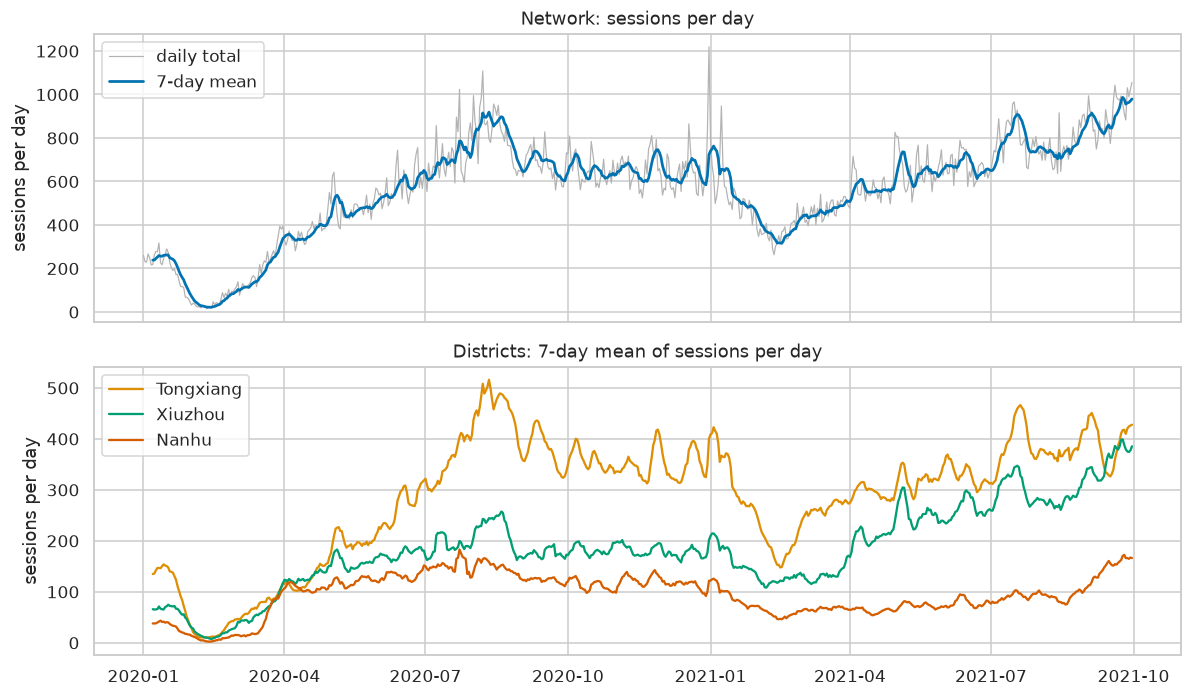

sessions per month


,network,Tongxiang,Xiuzhou,Nanhu
hour,,,,
2020-01,6217,3420,1845,952
2020-02,1391,663,498,230
2020-03,6392,2549,2228,1615
2020-04,11136,3937,3972,3227
2020-05,15033,6371,4943,3719
2020-06,17513,8259,5217,4037
2020-07,22032,11352,6027,4653
2020-08,25562,14174,6805,4583
2020-09,20231,11306,5258,3667


mean sessions per day, by quarter


,network,Tongxiang,Xiuzhou,Nanhu
2020-Q1,153.800,72.900,50.200,30.700
2020-Q2,480.000,204.000,155.300,120.700
2020-Q3,737.200,400.300,196.600,140.200
2020-Q4,656.100,356.400,182.200,117.600
2021-Q1,464.400,255.200,140.000,69.200
2021-Q2,632.300,315.800,244.700,71.800
2021-Q3,823.600,391.900,319.800,111.900


In [9]:
with timed("5 Exploratory analysis"):
    monthly = series[LEVELS].resample("MS").sum()
    monthly.index = monthly.index.strftime("%Y-%m")
    quarterly = daily.resample("QS").mean().round(1)
    quarterly.index = [f"{d.year}-Q{d.quarter}" for d in quarterly.index]

    fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    axes[0].plot(daily.index, daily["network"], color="0.7", lw=0.8, label="daily total")
    axes[0].plot(daily.index, daily["network"].rolling(7).mean(), color=LEVEL_COLORS["network"], lw=1.8,
                 label="7-day mean")
    axes[0].set_title("Network: sessions per day")
    for lvl in DISTRICTS:
        axes[1].plot(daily.index, daily[lvl].rolling(7).mean(), color=LEVEL_COLORS[lvl], lw=1.5, label=lvl)
    axes[1].set_title("Districts: 7-day mean of sessions per day")
    for ax in axes:
        ax.set_ylabel("sessions per day")
        ax.legend(loc="upper left")
    fig.tight_layout()
    save_fig("05_1_level_trend", fig)
    plt.show()

print("sessions per month")
display(monthly)
print("mean sessions per day, by quarter")
display(quarterly)
results["daily_mean_by_quarter"] = {q: {lvl: r(v, 1) for lvl, v in row.items()} for q, row in quarterly.iterrows()}

Demand grows over the two years but not smoothly. The network went from 154 sessions per day in the first quarter of
2020 to 737 in the third, fell to 464 in the first quarter of 2021, around the Spring Festival, and reached its
highest level, 824 per day, in the third quarter of 2021. Within each year demand rises from spring to late summer
and drops in winter. The districts do not move together: Xiuzhou keeps growing (197 sessions per day in 2020-Q3,
320 in 2021-Q3), while Nanhu falls from 140 to 112 and was at about 70 in the first half of 2021. A model trained on
one period meets a different level in the next, which is why the folds in Section 7 move forward in time.

### 5.2 Daily and weekly seasonality

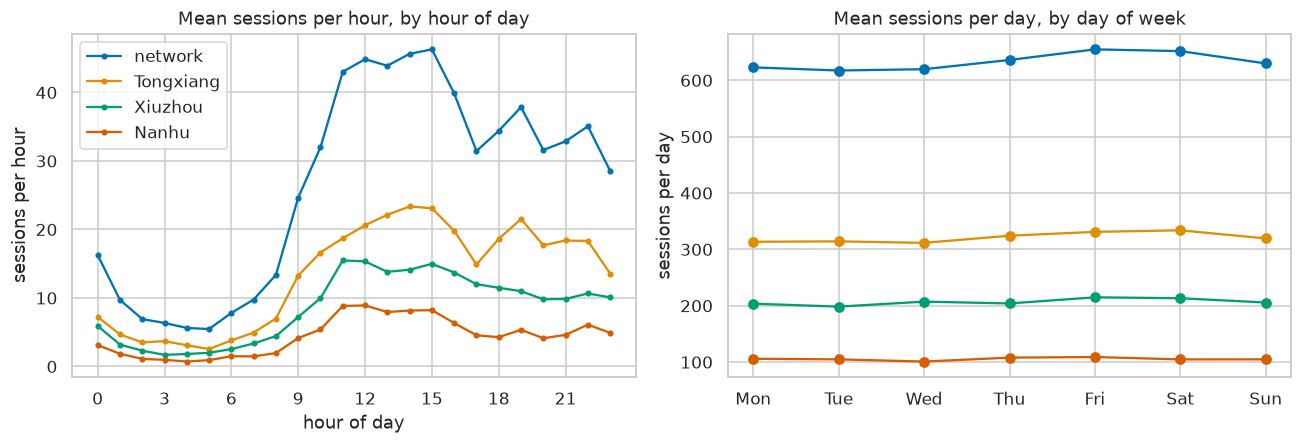

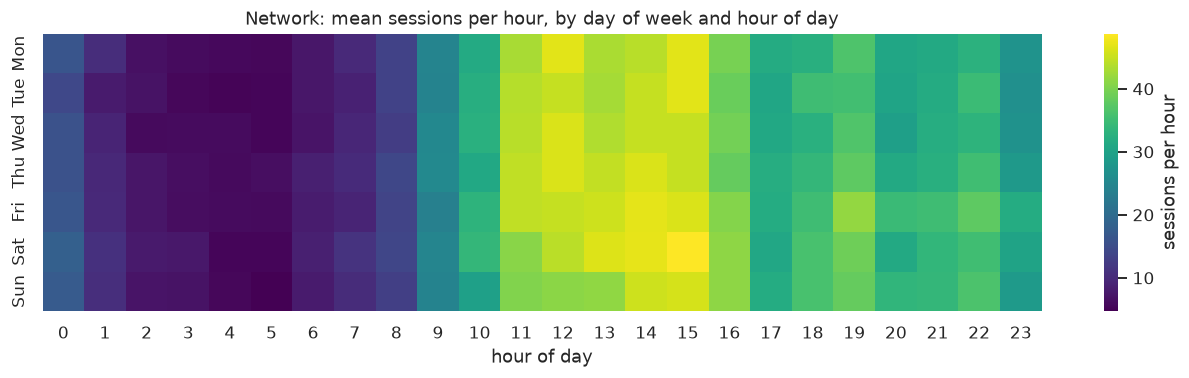

,peak hour,sessions at peak,quietest hour,sessions at quietest,peak / quietest,weekend / weekday (per day)
network,15,46.285,5,5.458,8.480,1.017
Tongxiang,14,23.354,5,2.542,9.187,1.024
Xiuzhou,11,15.474,3,1.690,9.158,1.019
Nanhu,12,8.901,4,0.714,12.476,0.992


In [10]:
with timed("5 Exploratory analysis"):
    by_hour = stable.groupby(stable.index.hour).mean()
    by_hour.index.name = "hour of day"
    DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    by_dow = stable_daily.groupby(stable_daily.index.dayofweek).mean()
    by_dow.index = DOW

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for lvl in LEVELS:
        axes[0].plot(by_hour.index, by_hour[lvl], marker="o", ms=3, color=LEVEL_COLORS[lvl], label=lvl)
        axes[1].plot(DOW, by_dow[lvl], marker="o", color=LEVEL_COLORS[lvl], label=lvl)
    axes[0].set(title="Mean sessions per hour, by hour of day", xlabel="hour of day", ylabel="sessions per hour",
                xticks=range(0, 24, 3))
    axes[1].set(title="Mean sessions per day, by day of week", ylabel="sessions per day")
    axes[0].legend()
    fig.tight_layout()
    save_fig("05_2_daily_weekly_profiles", fig)
    plt.show()

    heat = stable["network"].groupby([stable.index.dayofweek, stable.index.hour]).mean().unstack()
    heat.index = DOW
    fig, ax = plt.subplots(figsize=(12, 3.6))
    sns.heatmap(heat, cmap="viridis", ax=ax, cbar_kws={"label": "sessions per hour"})
    ax.set(title="Network: mean sessions per hour, by day of week and hour of day", xlabel="hour of day", ylabel="")
    fig.tight_layout()
    save_fig("05_2_hour_weekday_heatmap", fig)
    plt.show()

profile = pd.DataFrame({
    "peak hour": by_hour.idxmax(),
    "sessions at peak": by_hour.max(),
    "quietest hour": by_hour.idxmin(),
    "sessions at quietest": by_hour.min(),
    "peak / quietest": by_hour.max() / by_hour.min(),
    "weekend / weekday (per day)": by_dow.loc[["Sat", "Sun"]].mean() / by_dow.loc[DOW[:5]].mean(),
})
display(profile)
results["profile"] = {lvl: {k: r(v, 3) for k, v in row.items()} for lvl, row in profile.iterrows()}

The daily cycle is strong and the weekly one is weak. Network demand is lowest at 05:00 (5.5 sessions per hour) and
highest at 15:00 (46.3), 8.5 times more. It climbs from 07:00 to a plateau between 11:00 and 15:00, falls at 16:00 and 17:00,
and has smaller evening peaks at 19:00 and 22:00. The heatmap shows the same shape on every day of the week. Across the week
the differences are small: weekend days have only 1.7% more sessions per day than weekdays at network level, and in
Nanhu they have slightly fewer.

### 5.3 Autocorrelation and the seasonal period

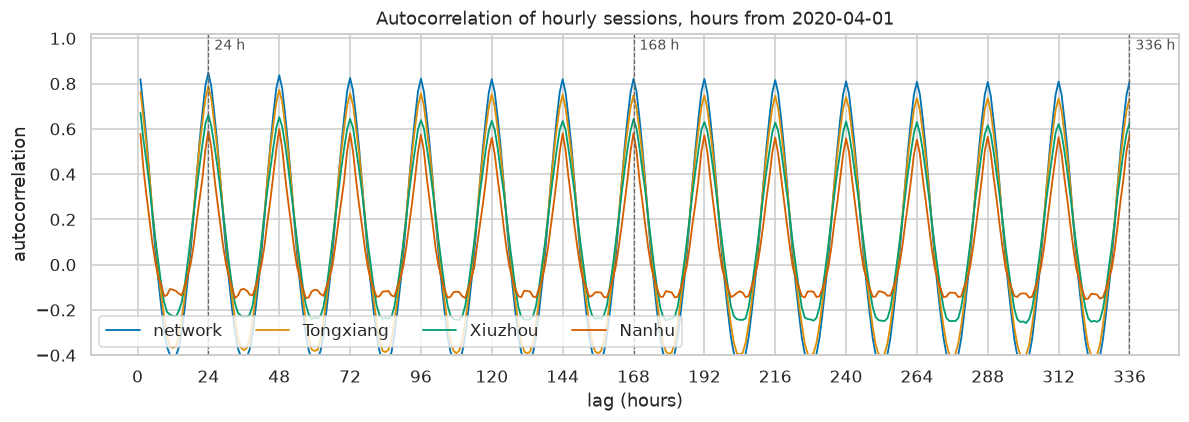

autocorrelation at selected lags


,network,Tongxiang,Xiuzhou,Nanhu
lag,,,,
1,0.819,0.762,0.670,0.578
24,0.848,0.788,0.662,0.590
48,0.836,0.772,0.651,0.599
168,0.821,0.748,0.642,0.581
336,0.808,0.733,0.626,0.570


in-sample MAE of the seasonal naive forecast, hours from 2020-04-01 (sessions per hour)


,m=24,m=168
network,7.123,7.626
Tongxiang,4.478,4.828
Xiuzhou,4.190,4.269
Nanhu,2.528,2.549


MASE seasonal period: m = 24


In [11]:
with timed("5 Exploratory analysis"):
    LAGS = range(1, 337)
    acf = pd.DataFrame({lvl: [stable[lvl].autocorr(k) for k in LAGS] for lvl in LEVELS},
                       index=pd.Index(LAGS, name="lag"))
    acf_table = acf.loc[[1, 24, 48, 168, 336]]

    snaive_mae = pd.DataFrame({
        f"m={m}": {lvl: (series[lvl] - series[lvl].shift(m)).loc[TRAIN_FROM:].abs().mean() for lvl in LEVELS}
        for m in (24, 168)
    })

    fig, ax = plt.subplots(figsize=(11, 4))
    for lvl in LEVELS:
        ax.plot(acf.index, acf[lvl], color=LEVEL_COLORS[lvl], lw=1.2, label=lvl)
    for lag in (24, 168, 336):
        ax.axvline(lag, color="0.4", ls="--", lw=0.8)
        ax.text(lag + 2, 0.95, f"{lag} h", fontsize=9, color="0.3")
    ax.set(title="Autocorrelation of hourly sessions, hours from 2020-04-01", xlabel="lag (hours)",
           ylabel="autocorrelation", ylim=(-0.4, 1.02), xticks=range(0, 337, 24))
    ax.legend(loc="lower left", ncol=4)
    fig.tight_layout()
    save_fig("05_3_autocorrelation", fig)
    plt.show()

print("autocorrelation at selected lags")
display(acf_table)
print("in-sample MAE of the seasonal naive forecast, hours from 2020-04-01 (sessions per hour)")
display(snaive_mae)

daily_wins = bool((acf_table.loc[24] > acf_table.loc[168]).all() and (snaive_mae["m=24"] < snaive_mae["m=168"]).all())
MASE_M = 24 if daily_wins else 168
print(f"MASE seasonal period: m = {MASE_M}")
results["acf"] = {str(k): {lvl: r(v) for lvl, v in row.items()} for k, row in acf_table.iterrows()}
results["snaive_in_sample_mae"] = {c: {lvl: r(v) for lvl, v in snaive_mae[c].items()} for c in snaive_mae}
results["mase_period"] = MASE_M
add_decision(
    "D05", "5.3",
    f"MASE is scaled with the daily seasonal naive forecast, m = {MASE_M}.",
    "From 2020-04-01 the autocorrelation at 24 hours is above that at 168 hours at every level ("
    + ", ".join(f"{lvl} {acf_table.at[24, lvl]:.3f} against {acf_table.at[168, lvl]:.3f}" for lvl in LEVELS)
    + "), and the in-sample seasonal naive MAE is lower with m = 24 (network "
    + f"{snaive_mae.at['network', 'm=24']:.2f} against {snaive_mae.at['network', 'm=168']:.2f} sessions per hour).",
)

The autocorrelation is the correlation of the series with itself shifted by a number of hours. It is not covered in
class; we reached it through research (Hyndman and Athanasopoulos, Forecasting: Principles and Practice, 3rd ed.,
Section 2.8). It peaks at every multiple of 24 hours, and the peak at 24 hours is higher than the one at 168 hours at
every level: 0.848 against 0.821 for the network, down to 0.590 against 0.581 for Nanhu. The seasonal naive
forecast, which repeats the value of one season earlier, agrees: on the hours from 2020-04-01 repeating yesterday's
hour gives a lower error than repeating last week's at every level (network 7.12 against 7.63 sessions per hour).
So the daily period is the stronger one, and we scale MASE with m = 24. The autocorrelations of the districts are
lower than the network's, because their counts are smaller and noisier.

### 5.4 Holidays

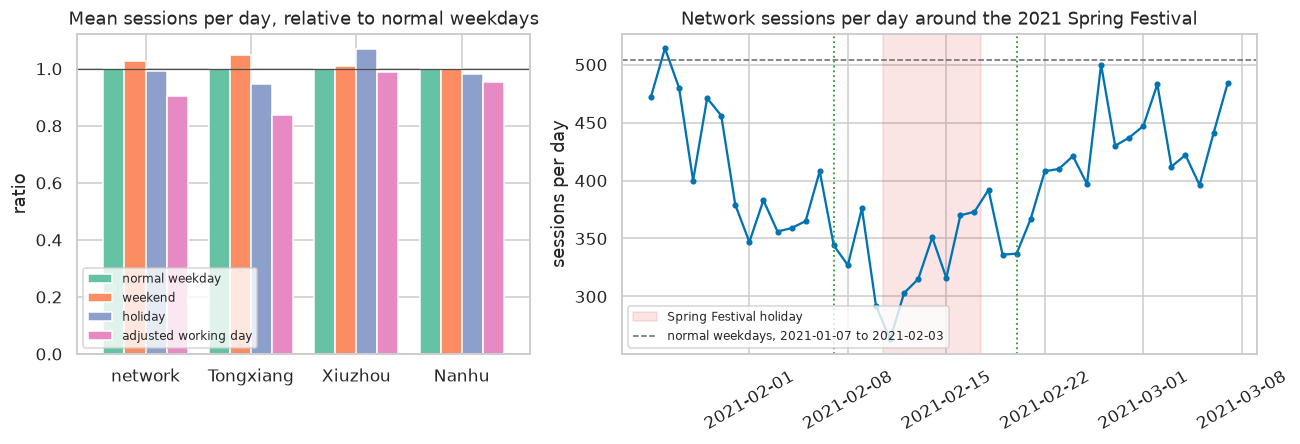

days of each type from 2020-04-01: {'normal weekday': np.int64(367), 'weekend': np.int64(127), 'holiday': np.int64(43), 'adjusted working day': np.int64(11)}
mean sessions per day by day type


,network,Tongxiang,Xiuzhou,Nanhu
day_type,,,,
normal weekday,630.785,319.937,205.180,105.668
weekend,647.780,335.000,207.205,105.575
holiday,626.209,303.000,219.349,103.860
adjusted working day,571.455,268.273,202.545,100.636


ratio to normal weekdays


,network,Tongxiang,Xiuzhou,Nanhu
day_type,,,,
normal weekday,1.000,1.000,1.000,1.000
weekend,1.027,1.047,1.010,0.999
holiday,0.993,0.947,1.069,0.983
adjusted working day,0.906,0.839,0.987,0.952


2021 Spring Festival week: 327 sessions per day against 504 on the normal weekdays of the four weeks before (-35.0%)


In [12]:
with timed("5 Exploratory analysis"):
    typed = stable_daily.join(DAY_TYPE)
    TYPES = ["normal weekday", "weekend", "holiday", "adjusted working day"]
    by_type = typed.groupby("day_type")[LEVELS].mean().reindex(TYPES)
    ratio = by_type / by_type.loc["normal weekday"]
    n_days = typed["day_type"].value_counts().reindex(TYPES)

    # 2021 Spring Festival against the normal weekdays of the four weeks before it
    sf_from, sf_to = pd.Timestamp("2021-02-11"), pd.Timestamp("2021-02-17")
    ref_days = typed.loc["2021-01-07":"2021-02-03"]
    sf_reference = ref_days.loc[ref_days["day_type"] == "normal weekday", "network"].mean()
    sf_mean = daily.loc[sf_from:sf_to, "network"].mean()
    window = daily.loc["2021-01-25":"2021-03-07", "network"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
    ratio.T.plot.bar(ax=axes[0], color=sns.color_palette("Set2", 4), rot=0, width=0.8)
    axes[0].axhline(1, color="0.3", lw=0.8)
    axes[0].set(title="Mean sessions per day, relative to normal weekdays", ylabel="ratio")
    axes[0].legend(fontsize=8)
    axes[1].plot(window.index, window.values, marker="o", ms=3, color=LEVEL_COLORS["network"])
    axes[1].axvspan(sf_from - pd.Timedelta(hours=12), sf_to + pd.Timedelta(hours=12), color="tab:red", alpha=0.12,
                    label="Spring Festival holiday")
    for day in ("2021-02-07", "2021-02-20"):
        axes[1].axvline(pd.Timestamp(day), color="tab:green", ls=":", lw=1.2)
    axes[1].axhline(sf_reference, color="0.4", ls="--", lw=1, label="normal weekdays, 2021-01-07 to 2021-02-03")
    axes[1].set(title="Network sessions per day around the 2021 Spring Festival", ylabel="sessions per day")
    axes[1].legend(fontsize=8, loc="lower left")
    axes[1].tick_params(axis="x", rotation=30)
    fig.tight_layout()
    save_fig("05_4_holidays", fig)
    plt.show()

print("days of each type from 2020-04-01:", dict(n_days))
print("mean sessions per day by day type")
display(by_type)
print("ratio to normal weekdays")
display(ratio)
print(f"2021 Spring Festival week: {sf_mean:.0f} sessions per day against {sf_reference:.0f} on the normal weekdays "
      f"of the four weeks before ({sf_mean / sf_reference - 1:+.1%})")
results["day_type_ratio"] = {t: {lvl: r(v, 3) for lvl, v in row.items()} for t, row in ratio.iterrows()}
results["spring_festival_2021"] = {"mean_per_day": r(sf_mean, 1), "reference_per_day": r(sf_reference, 1),
                                   "change": r(sf_mean / sf_reference - 1, 3)}
add_decision(
    "D06", "5.4",
    "Holidays, the Spring Festival included, are kept as legitimate variation and described to models by the "
    "holiday and adjusted working day flags; no day is removed.",
    f"From 2020-04-01, network demand on holidays is {ratio.at['holiday', 'network']:.2f} times that of normal weekdays "
    f"and {ratio.at['adjusted working day', 'network']:.2f} times on adjusted working days; the 2021 Spring Festival "
    f"week averaged {sf_mean:.0f} sessions per day against {sf_reference:.0f} ({sf_mean / sf_reference - 1:+.0%}).",
)

Over the 548 days from 2020-04-01, holidays as a whole hardly change network demand (0.99 times a normal weekday),
but this average hides two opposite effects. Tongxiang loses 5% on holidays while Xiuzhou gains 7%, and the Spring
Festival is a real break: in its 2021 week the network averaged 327 sessions per day against 504 on the normal
weekdays of the four weeks before, 35% less. Adjusted working days are not ordinary weekdays either; they have 9%
fewer sessions than normal weekdays at network level, 16% fewer in Tongxiang. The Spring Festival falls inside the
2021-Q1 validation quarter, so the evaluation will show how a forecaster copes with it. We keep every holiday as
legitimate variation and give models the two calendar flags instead of removing days.

### 5.5 The early-2020 restrictions and change over time

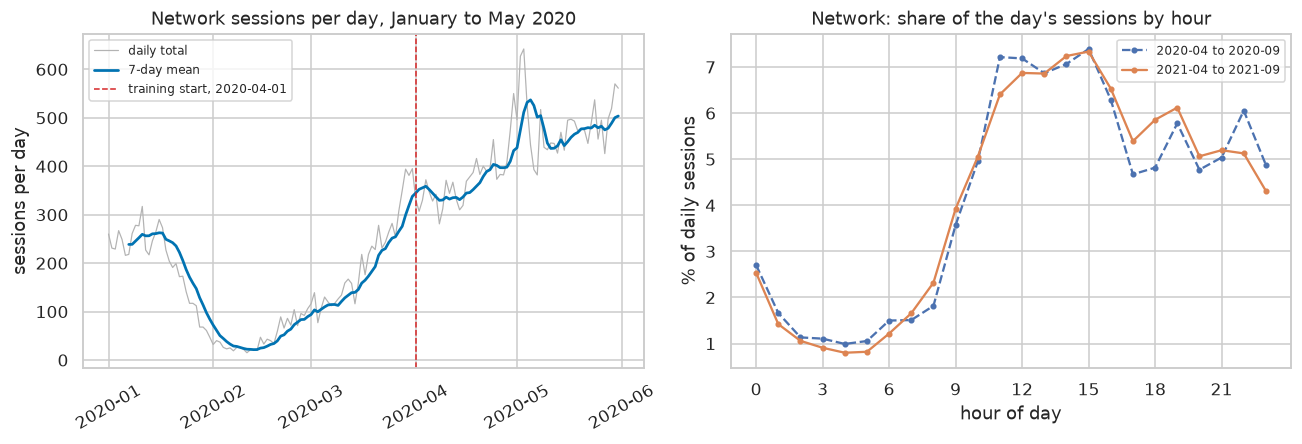

network sessions per month, January to May 2020


,network
hour,
2020-01,6217
2020-02,1391
2020-03,6392
2020-04,11136
2020-05,15033


change in mean sessions per day, April-September 2021 against April-September 2020


,change (%)
network,19.600
Tongxiang,17.000
Xiuzhou,60.400
Nanhu,-29.500


largest difference in the hourly share between the two periods: 1.04 percentage points


In [13]:
with timed("5 Exploratory analysis"):
    early = daily.loc["2020-01-01":"2020-05-31", "network"]
    month_totals = monthly.loc[["2020-01", "2020-02", "2020-03", "2020-04", "2020-05"], "network"]
    shape = {}
    for label, lo, hi in [("2020-04 to 2020-09", "2020-04-01", "2020-09-30 23:00"),
                          ("2021-04 to 2021-09", "2021-04-01", "2021-09-30 23:00")]:
        part = series.loc[lo:hi, "network"]
        shape[label] = part.groupby(part.index.hour).mean()
    shape = pd.DataFrame(shape)
    share = shape / shape.sum()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].plot(early.index, early.values, color="0.7", lw=0.8, label="daily total")
    axes[0].plot(early.index, early.rolling(7).mean(), color=LEVEL_COLORS["network"], lw=1.8, label="7-day mean")
    axes[0].axvline(TRAIN_FROM, color="tab:red", ls="--", lw=1, label="training start, 2020-04-01")
    axes[0].set(title="Network sessions per day, January to May 2020", ylabel="sessions per day")
    axes[0].legend(fontsize=8)
    axes[0].tick_params(axis="x", rotation=30)
    for col, style in zip(share.columns, ["--", "-"]):
        axes[1].plot(share.index, share[col] * 100, ls=style, marker="o", ms=3, label=col)
    axes[1].set(title="Network: share of the day's sessions by hour", xlabel="hour of day",
                ylabel="% of daily sessions", xticks=range(0, 24, 3))
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    save_fig("05_5_change_over_time", fig)
    plt.show()

growth = daily.loc["2021-04-01":"2021-09-30"].mean() / daily.loc["2020-04-01":"2020-09-30"].mean() - 1
print("network sessions per month, January to May 2020")
display(month_totals.to_frame())
print("change in mean sessions per day, April-September 2021 against April-September 2020")
display((growth * 100).round(1).to_frame("change (%)"))
print(f"largest difference in the hourly share between the two periods: {(share.diff(axis=1).iloc[:, 1].abs().max()) * 100:.2f} "
      "percentage points")
results["month_totals_2020"] = {k: int(v) for k, v in month_totals.items()}
results["growth_2021_vs_2020_apr_sep"] = {lvl: r(v, 3) for lvl, v in growth.items()}
add_decision(
    "D07", "5.5",
    "Training rows start on 2020-04-01, which confirms the Project 1 boundary; January to March 2020 serve only as "
    "lag history.",
    f"Network sessions were {month_totals['2020-01']:,} in January 2020, {month_totals['2020-02']:,} in February and "
    f"{month_totals['2020-03']:,} in March, and {month_totals['2020-04']:,} in April; the February collapse belongs to "
    "the first COVID-19 restrictions and not to the demand the models must learn.",
)

February 2020 had 1,391 network sessions, against 6,217 in January and 6,392 in March. These are the first COVID-19
restrictions in China, and demand only came back in April (11,136 sessions) and May (15,033). Those months describe an
exceptional situation, not the demand a forecaster will meet, so training rows start on 2020-04-01, as in Project 1,
and January to March 2020 serve only as lag history for the first training rows.

After April 2020 the level keeps changing but the daily shape does not. Between April-September 2020 and the same
months of 2021 network demand per day grew by 19.6%, Xiuzhou by 60.4%, Tongxiang by 17.0%, while Nanhu fell by
29.5%. The share of the day's sessions in each hour moved by at most 1.04 percentage points. A forecaster therefore
has to follow the level, while the shape of the day can be learnt from the whole training window.

### 5.6 Districts

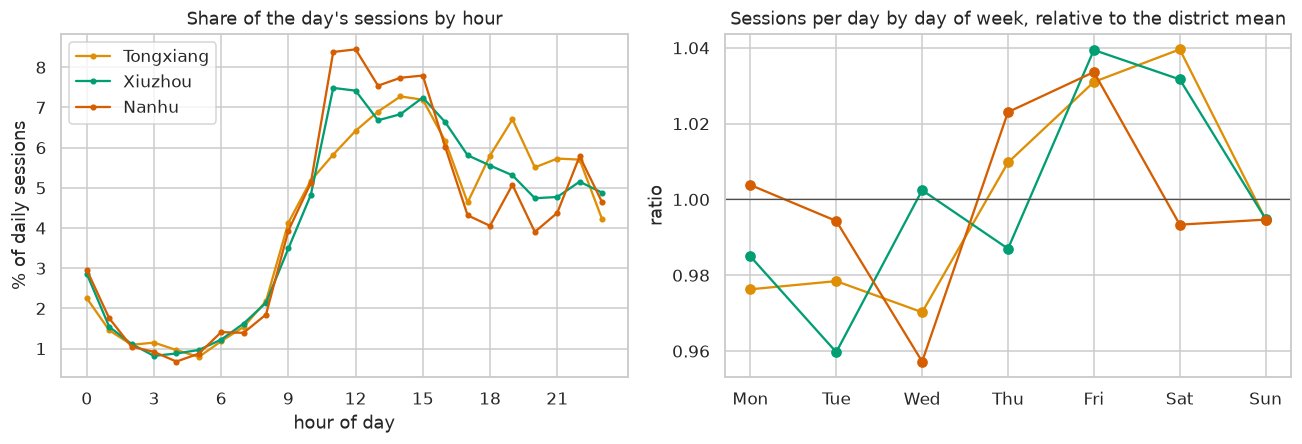

,share of sessions,mean per hour,variance / mean,share of zero hours,peak hour,weekend / weekday
Tongxiang,0.507,13.378,6.916,0.021,14,1.024
Xiuzhou,0.326,8.613,6.028,0.065,11,1.019
Nanhu,0.166,4.392,3.945,0.150,12,0.992


In [14]:
with timed("5 Exploratory analysis"):
    totals = stable[DISTRICTS].sum()
    dist = pd.DataFrame({
        "share of sessions": totals / totals.sum(),
        "mean per hour": stable[DISTRICTS].mean(),
        "variance / mean": stable[DISTRICTS].var() / stable[DISTRICTS].mean(),
        "share of zero hours": stable[DISTRICTS].eq(0).mean(),
        "peak hour": by_hour[DISTRICTS].idxmax(),
        "weekend / weekday": profile.loc[DISTRICTS, "weekend / weekday (per day)"],
    })
    hour_share = by_hour[DISTRICTS] / by_hour[DISTRICTS].sum()
    dow_index = by_dow[DISTRICTS] / by_dow[DISTRICTS].mean()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for lvl in DISTRICTS:
        axes[0].plot(hour_share.index, hour_share[lvl] * 100, marker="o", ms=3, color=LEVEL_COLORS[lvl], label=lvl)
        axes[1].plot(DOW, dow_index[lvl], marker="o", color=LEVEL_COLORS[lvl], label=lvl)
    axes[0].set(title="Share of the day's sessions by hour", xlabel="hour of day", ylabel="% of daily sessions",
                xticks=range(0, 24, 3))
    axes[1].axhline(1, color="0.3", lw=0.8)
    axes[1].set(title="Sessions per day by day of week, relative to the district mean", ylabel="ratio")
    axes[0].legend()
    fig.tight_layout()
    save_fig("05_6_districts", fig)
    plt.show()

display(dist)
results["districts"] = {lvl: {k: r(v) for k, v in row.items()} for lvl, row in dist.iterrows()}

The three districts differ mainly in size. From 2020-04-01 Tongxiang holds 50.7% of the sessions, Xiuzhou 32.6% and
Nanhu 16.6%. Their hourly counts are overdispersed: the variance is 6.9 times the mean in Tongxiang, 6.0 in Xiuzhou
and 3.9 in Nanhu, more than a simple random arrival process would give, because the daily cycle moves the mean
through the day. The smallest district has the most empty hours (15.0% in Nanhu). The shapes are close but not equal:
Xiuzhou and Nanhu peak before noon (11:00 and 12:00), Tongxiang in the early afternoon (14:00) with a stronger
evening rise, and none of the three has a marked weekly pattern. One shared model with the level as an input can
learn these differences, while MASE puts the three districts on the same scale.

### 5.7 Weather

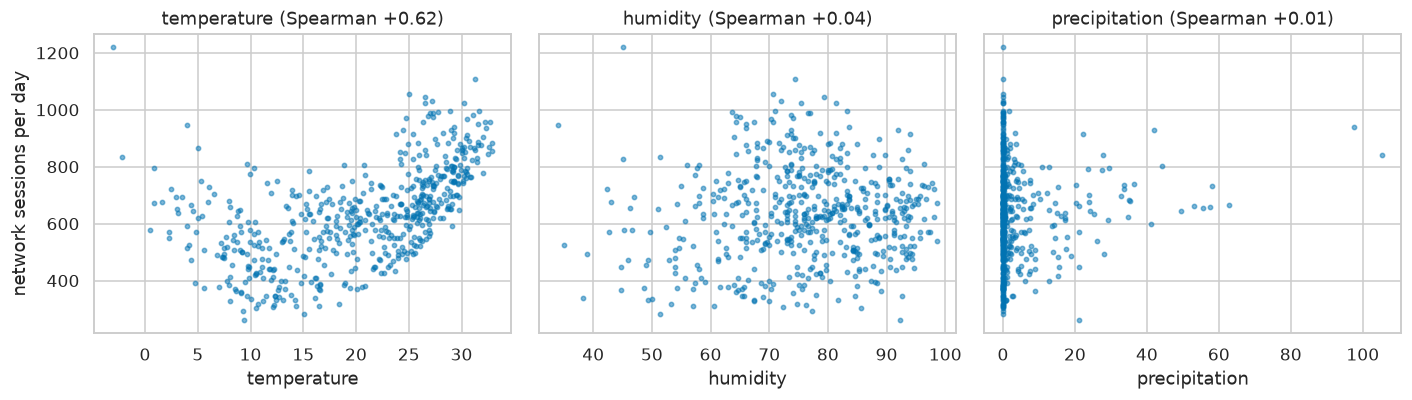

distinct values per day and district (maximum over days): 1


,Pearson,Spearman
temperature,0.533,0.625
humidity,0.059,0.045
precipitation,0.087,0.012


rainy days: 267 of 548; mean sessions per day on rainy days are 0.98 times those of dry days


In [15]:
with timed("5 Exploratory analysis"):
    WEATHER = {"Temperature(℃)": "temperature", "Relative Humidity(%)": "humidity", "Precipitation(mm)": "precipitation"}
    per_district = (data.assign(date=data["start"].dt.normalize())
                        .groupby(["date", "District Name"])[list(WEATHER)].first()
                        .apply(pd.to_numeric))
    one_value = (data.assign(date=data["start"].dt.normalize())
                     .groupby(["date", "District Name"])[list(WEATHER)].nunique().max().max())
    weather = per_district.groupby("date").mean().rename(columns=WEATHER)
    wd = stable_daily[["network"]].join(weather, how="inner")
    corr = pd.DataFrame({
        "Pearson": wd.drop(columns="network").corrwith(wd["network"]),
        "Spearman": wd.drop(columns="network").corrwith(wd["network"], method="spearman"),
    })
    rainy = wd["precipitation"] > 0
    rain_ratio = wd.loc[rainy, "network"].mean() / wd.loc[~rainy, "network"].mean()

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
    for ax, col in zip(axes, ["temperature", "humidity", "precipitation"]):
        ax.scatter(wd[col], wd["network"], s=8, alpha=0.5, color=LEVEL_COLORS["network"])
        ax.set(title=f"{col} (Spearman {corr.at[col, 'Spearman']:+.2f})", xlabel=col)
    axes[0].set_ylabel("network sessions per day")
    fig.tight_layout()
    save_fig("05_7_weather", fig)
    plt.show()

print(f"distinct values per day and district (maximum over days): {one_value}")
display(corr)
print(f"rainy days: {int(rainy.sum())} of {len(wd)}; mean sessions per day on rainy days are "
      f"{rain_ratio:.2f} times those of dry days")
results["weather_corr"] = {col: {k: r(v, 3) for k, v in row.items()} for col, row in corr.iterrows()}
results["rain_ratio"] = r(rain_ratio, 3)
add_decision(
    "D08", "5.7",
    "Weather stays an exogenous candidate: a model may use it only as a daily forecast known at issuance, and "
    "Task 2 tests whether it helps.",
    f"Weather is recorded once per day and district; from 2020-04-01 its Spearman correlation with daily network "
    f"demand is {corr.at['temperature', 'Spearman']:+.2f} for temperature, {corr.at['humidity', 'Spearman']:+.2f} for "
    f"humidity and {corr.at['precipitation', 'Spearman']:+.2f} for precipitation; rainy days have "
    f"{rain_ratio:.2f} times the sessions of dry days.",
)

Weather is recorded once per day for each district (every session of a district on a given day carries the same
values), so we can only build daily weather. Temperature is the one variable that moves with demand: its Spearman
correlation with daily network sessions is 0.62. Most of it is seasonal, since both temperature and demand rise from
spring to summer and both fell in the winter of 2021, so this does not show that warm days cause charging. Humidity
(0.04) and precipitation (0.01) show no relation, and rainy days have 0.98 times the sessions of dry days.

Using weather would also need a forecast. At 00:00 the weather of the coming day is not observed, so a model could
only use a daily weather forecast, and the file holds observed values. We leave weather as an exogenous candidate,
to be tested in Task 2 under that stated assumption.

These findings fix the next two sections. The strong daily cycle and the 24-hour autocorrelation give the
seasonal period of MASE and the most useful lags. The weak weekly pattern means a weekly baseline is not expected
to beat the daily one. Holidays and adjusted working days enter as calendar flags, the training rows start on
2020-04-01, and the changing level is why we evaluate forward in time.

## 6 Forecasting formulation

### 6.1 Issuance schedule

The forecaster issues one forecast per day, at 00:00, using the data up to the hour that starts at 23:00 of the
previous day. The forecast covers the 24 hours of that day, so horizon 1 is 00:00 to 01:00 and horizon 24 is 23:00 to
24:00; horizon h is always clock hour h-1. One forecast a day matches the daily planning of capacity and resources that the
statement describes. At midnight the same hour of the previous day is already known for every horizon, and Section
5.3 showed that this is the strongest single lag. The limitation is that an operator might want the forecast earlier,
for example in the afternoon before; that would push the shortest usable lag further back.

In [16]:
add_decision(
    "D09", "6.1",
    "Forecasts are issued once a day at 00:00 with the data up to the hour starting at 23:00 of the previous day, "
    "for the 24 hours of the issuance day; horizon h is clock hour h-1.",
    "Daily planning needs one forecast per day; at midnight the same hour of the previous day is known for every "
    f"horizon, and that lag has autocorrelation {acf_table.at[24, 'network']:.3f} at network level (Section 5.3).",
)

### 6.2 Multi-step strategy and forecast rows

There are three ways to produce 24 values (Ben Taieb et al., 2012, a review we reached through research, since
multi-step strategies are not covered in class). A recursive forecaster predicts one hour and feeds its prediction
back as an input for the next, so its errors pile up over the day. A direct forecaster with one model per horizon
needs 24 models, each trained on one 24th of the data. We use the direct strategy with one shared model: each target
hour of an issuance is one row, all inputs of the row are known at 00:00, the hour of the day is one of the inputs,
and no forecast is ever fed back.

The function below builds these forecast rows for any set of issuance days. Each row holds the issuance day, the
level, the horizon, the target hour, the observed target and the inputs. Some inputs are counted back from the target
hour (the value 24 hours before, the mean of the same hour over the previous days); others are counted back from the
issuance (the total of the previous day, of the previous week). Before building anything, the function works out the
latest hour each input reads and asserts that it is before the issuance, for every row. A row whose target hour or
any input hour falls in a data gap is left out.

In [17]:
TARGET_LAGS = {  # input -> lags in hours, counted back from the target hour
    "lag_24": [24],
    "lag_48": [48],
    "lag_168": [168],
    "same_hour_mean_7d": [24 * k for k in range(1, 8)],
    "same_hour_mean_4w": [168 * k for k in range(1, 5)],
}
ISSUANCE_WINDOWS = {  # input -> (first day, last day) of a window of whole days, relative to the issuance day D
    "prev_day_total": (-1, -1),
    "prev_7day_total": (-7, -1),
}
CALENDAR_INPUTS = ["hour_of_day", "day_of_week", "is_holiday", "is_adjusted_workday", "month"]
INPUTS = [*TARGET_LAGS, *ISSUANCE_WINDOWS, *CALENDAR_INPUTS]


def make_forecast_rows(series, calendar, days, levels=LEVELS):
    """One row per (issuance day, level, horizon) with the target and the inputs known at the issuance D 00:00."""
    days = pd.DatetimeIndex(days)
    issuance = pd.DatetimeIndex(np.repeat(days.values, 24))
    horizon = np.tile(np.arange(1, 25), len(days))
    target_hour = issuance + pd.to_timedelta(horizon - 1, unit="h")

    # leakage test: the latest hour any input reads must be before the issuance
    latest = [target_hour - pd.Timedelta(hours=min(lags)) for lags in TARGET_LAGS.values()]
    latest += [issuance + pd.Timedelta(days=last, hours=23) for _, last in ISSUANCE_WINDOWS.values()]
    latest_input_hour = pd.DatetimeIndex(np.max(np.vstack([t.values for t in latest]), axis=0))
    assert (latest_input_hour < issuance).all(), "an input reads an hour at or after the issuance"

    earliest = min(days[0] - pd.Timedelta(hours=max(max(l) for l in TARGET_LAGS.values())),
                   days[0] + pd.Timedelta(days=min(first for first, _ in ISSUANCE_WINDOWS.values())))
    assert earliest >= series.index[0] and target_hour[-1] <= series.index[-1], "not enough history in the series"

    gap = series["is_gap"]
    daily_total = series[levels].resample("D").sum()
    daily_gap = gap.resample("D").max()
    cal = calendar.set_index("date").reindex(issuance.normalize())

    bad = gap.reindex(target_hour).to_numpy(dtype=bool)
    for lags in TARGET_LAGS.values():
        for k in lags:
            bad = bad | gap.reindex(target_hour - pd.Timedelta(hours=k)).to_numpy(dtype=bool)
    for first, last in ISSUANCE_WINDOWS.values():
        for o in range(first, last + 1):
            bad = bad | daily_gap.reindex(issuance + pd.Timedelta(days=o)).to_numpy(dtype=bool)

    frames = []
    for lvl in levels:
        y = series[lvl]
        f = pd.DataFrame({"issuance": issuance, "level": lvl, "horizon": horizon, "target_hour": target_hour,
                          "target": y.reindex(target_hour).to_numpy()})
        for name, lags in TARGET_LAGS.items():
            f[name] = np.mean([y.reindex(target_hour - pd.Timedelta(hours=k)).to_numpy() for k in lags], axis=0)
        for name, (first, last) in ISSUANCE_WINDOWS.items():
            f[name] = np.sum([daily_total[lvl].reindex(issuance + pd.Timedelta(days=o)).to_numpy()
                              for o in range(first, last + 1)], axis=0)
        f["hour_of_day"] = horizon - 1
        f["day_of_week"] = cal["day_of_week"].to_numpy()
        f["is_holiday"] = cal["is_holiday"].to_numpy()
        f["is_adjusted_workday"] = cal["is_adjusted_workday"].to_numpy()
        f["month"] = issuance.month
        frames.append(f[~bad])
    rows = pd.concat(frames, ignore_index=True)
    assert (rows["hour_of_day"] == rows["target_hour"].dt.hour).all()
    assert not rows[["target", *INPUTS]].isna().any().any()
    return rows


with timed("6 Forecasting formulation"):
    DEV_DAYS = pd.date_range(TRAIN_FROM, "2021-09-30", freq="D")
    all_rows = make_forecast_rows(series, calendar, DEV_DAYS)
    per_issue = all_rows.groupby(["issuance", "level"]).size()
    assert results["gap_hours"] > 0 or (per_issue == 24).all()

print(f"{len(all_rows):,} forecast rows: {len(DEV_DAYS)} issuances x {len(LEVELS)} levels x 24 horizons; "
      f"{len(DEV_DAYS) * 24 * len(LEVELS) - len(all_rows)} rows left out because of gaps")
display(all_rows.head(3))
add_decision(
    "D10", "6.2",
    "The 24 values come from a direct strategy with one shared model: one row per (issuance, level, horizon), inputs "
    "known at 00:00 only, hour of day as an input, no forecast fed back as an input.",
    f"The layout gives {len(all_rows):,} development rows; 24 separate models would each see 1/24 of them, and a "
    "recursive forecast would feed its own errors into later hours of the day (Ben Taieb et al., 2012).",
)

52,608 forecast rows: 548 issuances x 4 levels x 24 horizons; 0 rows left out because of gaps


,issuance,level,horizon,target_hour,target,lag_24,lag_48,lag_168,same_hour_mean_7d,same_hour_mean_4w,prev_day_total,prev_7day_total,hour_of_day,day_of_week,is_holiday,is_adjusted_workday,month
0,2020-04-01,network,1,2020-04-01 00:00:00,5,10.000,11.000,6.000,6.429,3.500,395,2364,0,2,False,False,4
1,2020-04-01,network,2,2020-04-01 01:00:00,3,8.000,9.000,1.000,5.143,2.500,395,2364,1,2,False,False,4
2,2020-04-01,network,3,2020-04-01 02:00:00,0,7.000,5.000,1.000,2.571,1.000,395,2364,2,2,False,False,4


### 6.3 Predictor catalogue

The catalogue lists every candidate input with its kind (historical observation, known future information or
exogenous variable), how it is anchored, when it becomes known, its smallest lag and our decision. A lag counted
back from the target hour is known at 00:00 for every horizon only if it is at least 24 hours: for horizon 24 (23:00)
a lag of 23 hours would read 00:00 of the same day, which has not happened yet at issuance. Windows counted back from
the issuance end with the hour starting at 23:00 of the previous day and are known for every horizon. The level of a
row is known future information, since it is fixed before any forecast is made.

In [18]:
with timed("6 Forecasting formulation"):
    H, KF, EX = "historical", "known future", "exogenous"
    cat = [
        ("lag_24", H, "target", "sessions at the same hour of the previous day", 24, "include",
         "Strongest single lag (Section 5.3) and known for every horizon."),
        ("lag_48", H, "target", "sessions at the same hour two days before", 48, "include",
         "A second daily value smooths one unusual day."),
        ("lag_168", H, "target", "sessions at the same hour one week before", 168, "include",
         "Carries the weekday pattern of the target day."),
        ("same_hour_mean_7d", H, "target", "mean of the same hour over the 7 previous days", 24, "include",
         "Averaging removes part of the hour-to-hour noise."),
        ("same_hour_mean_4w", H, "target", "mean of the same hour and weekday over the 4 previous weeks", 168, "include",
         "Weekday-matched level; also the mean_4w baseline."),
        ("prev_day_total", H, "issuance", "sessions on day D-1 (window ends with the hour starting at D-1 23:00)",
         None, "include", "Most recent daily level, complete at 00:00."),
        ("prev_7day_total", H, "issuance", "sessions on days D-7 to D-1", None, "include",
         "Weekly level, less affected by one unusual day."),
        ("hour_of_day", KF, "none", "clock hour of the target, equal to the horizon minus 1", None, "include",
         "Main daily pattern (Section 5.2)."),
        ("day_of_week", KF, "none", "weekday of the target day", None, "include", "Weekly pattern (Section 5.2)."),
        ("is_holiday", KF, "none", "public holiday from the State Council calendar", None, "include",
         "Holiday effect (Section 5.4)."),
        ("is_adjusted_workday", KF, "none", "weekend day worked in exchange for a holiday", None, "include",
         "They differ from both weekdays and weekends (Section 5.4)."),
        ("month", KF, "none", "calendar month of the target day", None, "include", "Slow seasonal change."),
        ("level", KF, "none", "network or district of the row, fixed before any forecast", None, "include",
         "Lets one shared model serve the four levels."),
        ("daily temperature, humidity, precipitation", EX, "none",
         "known at 00:00 only as a weather forecast for day D", None, "candidate",
         "Usable only if a daily weather forecast is assumed known at 00:00; Task 2 tests it (Section 5.7)."),
        ("observed weather of day D", EX, "none", "recorded during the target day, after the issuance", None, "exclude",
         "Observed future weather is not available at issuance."),
        ("lags 1 to 23 hours", H, "target", "known only for the horizons shorter than the lag", 1, "exclude",
         "Not available for every horizon under midnight issuance."),
        ("any session starting after D 00:00", H, "target", "after the issuance", 0, "exclude", "Leakage."),
        ("energy, costs, payment amounts", H, "none", "recorded when a session ends", None, "exclude",
         "Describe sessions, not how many start; not needed for the counts."),
        ("end cause and fault flags", H, "none", "recorded when a session ends", None, "exclude",
         "Outcomes of single sessions, known only after they end."),
        ("user and post identifiers, location type", H, "none", "attributes of single sessions", None, "exclude",
         "The series aggregate over users and posts."),
    ]
    catalogue = pd.DataFrame(cat, columns=["name", "kind", "anchor", "availability", "min_lag_hours", "decision",
                                           "reason"])
    catalogue["min_lag_hours"] = catalogue["min_lag_hours"].astype("Int64")

    assert catalogue["kind"].isin([H, KF, EX]).all()
    assert catalogue["decision"].isin(["include", "candidate", "exclude"]).all()
    inc = catalogue[catalogue["decision"] == "include"]
    inc_target = inc[inc["anchor"] == "target"]
    assert (inc_target["min_lag_hours"] >= 24).all()
    assert all(min(TARGET_LAGS[n]) == lag for n, lag in inc_target[["name", "min_lag_hours"]].values)
    assert all(ISSUANCE_WINDOWS[n][1] == -1 for n in inc.loc[inc["anchor"] == "issuance", "name"])
    assert set(inc["name"]) - {"level"} == set(INPUTS)
    catalogue.to_csv(OUT / "task1_predictor_catalogue.csv", index=False)

with pd.option_context("display.max_colwidth", 70):
    display(catalogue)
add_decision(
    "D11", "6.3",
    f"{len(inc)} inputs are included, weather is a candidate and {int((catalogue['decision'] == 'exclude').sum())} "
    "groups are excluded; each is labelled historical, known future or exogenous.",
    "Every included target-anchored lag is at least 24 hours, every issuance-anchored window ends with the hour "
    "starting at D-1 23:00, and make_forecast_rows asserts for every row that no input reads an hour at or after "
    "the issuance.",
)

,name,kind,anchor,availability,min_lag_hours,decision,reason
0,lag_24,historical,target,sessions at the same hour of the previous day,24,include,Strongest single lag (Section 5.3) and known for every horizon.
1,lag_48,historical,target,sessions at the same hour two days before,48,include,A second daily value smooths one unusual day.
2,lag_168,historical,target,sessions at the same hour one week before,168,include,Carries the weekday pattern of the target day.
3,same_hour_mean_7d,historical,target,mean of the same hour over the 7 previous days,24,include,Averaging removes part of the hour-to-hour noise.
4,same_hour_mean_4w,historical,target,mean of the same hour and weekday over the 4 previous weeks,168,include,Weekday-matched level; also the mean_4w baseline.
5,prev_day_total,historical,issuance,sessions on day D-1 (window ends with the hour starting at D-1 23:00),<NA>,include,"Most recent daily level, complete at 00:00."
6,prev_7day_total,historical,issuance,sessions on days D-7 to D-1,<NA>,include,"Weekly level, less affected by one unusual day."
7,hour_of_day,known future,none,"clock hour of the target, equal to the horizon minus 1",<NA>,include,Main daily pattern (Section 5.2).
8,day_of_week,known future,none,weekday of the target day,<NA>,include,Weekly pattern (Section 5.2).
9,is_holiday,known future,none,public holiday from the State Council calendar,<NA>,include,Holiday effect (Section 5.4).


### 6.4 A worked issuance

The figure shows one issuance, Monday 2021-03-15 at 00:00. Everything to the left of the red line is known; the
orange part is the 24 hours to forecast. The circles mark the hours read by the lags of horizon 1 (00:00) and the
squares those of horizon 24 (23:00); the shaded day is the window of the previous day's total.

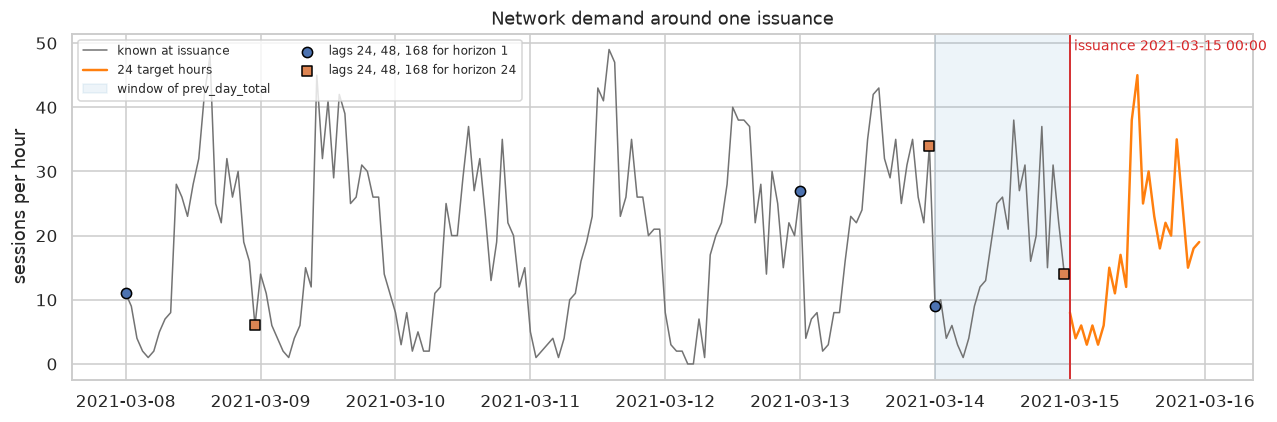

,8352,8375
issuance,2021-03-15 00:00:00,2021-03-15 00:00:00
level,network,network
horizon,1,24
target_hour,2021-03-15 00:00:00,2021-03-15 23:00:00
target,8,19
lag_24,9.000,14.000
lag_48,27.000,34.000
lag_168,11.000,6.000
same_hour_mean_7d,11.714,17.286
same_hour_mean_4w,9.250,14.500


In [19]:
with timed("6 Forecasting formulation"):
    D = pd.Timestamp("2021-03-15")
    view = series.loc[D - pd.Timedelta(days=7):D + pd.Timedelta(hours=23), "network"]
    known, future = view.loc[:D - pd.Timedelta(hours=1)], view.loc[D:]

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(known.index, known.values, color="0.45", lw=1, label="known at issuance")
    ax.plot(future.index, future.values, color="tab:orange", lw=1.6, label="24 target hours")
    ax.axvline(D, color="tab:red", lw=1.2)
    ax.text(D, ax.get_ylim()[1] * 0.95, " issuance 2021-03-15 00:00", color="tab:red", fontsize=9)
    ax.axvspan(D - pd.Timedelta(days=1), D - pd.Timedelta(hours=0.02), color="tab:blue", alpha=0.08,
               label="window of prev_day_total")
    for h, marker in [(1, "o"), (24, "s")]:
        t = D + pd.Timedelta(hours=h - 1)
        hours_used = [t - pd.Timedelta(hours=k) for k in (24, 48, 168)]
        ax.scatter(hours_used, view.reindex(hours_used), marker=marker, s=45, zorder=3, edgecolor="black",
                   label=f"lags 24, 48, 168 for horizon {h}")
    ax.set(title="Network demand around one issuance", ylabel="sessions per hour")
    ax.legend(fontsize=8, loc="upper left", ncol=2)
    fig.tight_layout()
    save_fig("06_4_worked_issuance", fig)
    plt.show()

example = all_rows[(all_rows["issuance"] == D) & (all_rows["level"] == "network")]
display(example.iloc[[0, -1]].T)

The two rows printed above are the first and last rows of that issuance at network level. Horizon 1 (00:00) had 8
sessions, against 9 at the same hour the day before and 11 a week before; horizon 24 (23:00) had 19, against 14 the
day before. The previous day's total, 413 sessions, and the previous week's, 3,216, are the same in both rows, as they
should be, because they only depend on the issuance.

## 7 Evaluation protocol

### 7.1 Test period

The test period is the last quarter of the data, 2021-10-01 to 2021-12-31, chosen from the coverage facts in Section
2.2. Its 80,081 rows were dropped right after reading. No figure, table or decision in this task uses them, and no
baseline is scored on them; the test is evaluated once, by the final model of the project.

In [20]:
print(f"test period: {TEST_FROM.date()} to 2021-12-31, {test_rows:,} rows, not read beyond their count and not scored")

test period: 2021-10-01 to 2021-12-31, 80,081 rows, not read beyond their count and not scored


### 7.2 Folds

We keep the four expanding-window folds of Project 1. Every fold trains from 2020-04-01 up to the start of one
validation quarter and validates on that quarter: 2020-Q4, 2021-Q1, 2021-Q2 and 2021-Q3. Time order is kept, as the
evaluation deck (MINDD-04) requires for data that change over time, and the windows grow so later folds learn from
more history. Each validation day is one issuance at 00:00, so every model is scored on the same issuances. Project 1
purged a few sessions at each boundary; here demand is counted by start hour, nothing crosses a boundary, and no gap
is needed. Hours before 2020-04-01 are used only as lag history.

In [21]:
with timed("7 Evaluation protocol"):
    FOLDS = pd.DataFrame([
        {"fold": 1, "train_from": "2020-04-01", "train_before": "2020-10-01",
         "validate_from": "2020-10-01", "validate_before": "2021-01-01"},
        {"fold": 2, "train_from": "2020-04-01", "train_before": "2021-01-01",
         "validate_from": "2021-01-01", "validate_before": "2021-04-01"},
        {"fold": 3, "train_from": "2020-04-01", "train_before": "2021-04-01",
         "validate_from": "2021-04-01", "validate_before": "2021-07-01"},
        {"fold": 4, "train_from": "2020-04-01", "train_before": "2021-07-01",
         "validate_from": "2021-07-01", "validate_before": "2021-10-01"},
    ])
    DATE_COLS = ["train_from", "train_before", "validate_from", "validate_before"]

    p1_protocol = Path("../project1/prepared/task2_protocol.json")
    if p1_protocol.exists():
        p1_folds = json.loads(p1_protocol.read_text())["temporal"]["folds"]
        assert [{k: f[k] for k in ["fold", *DATE_COLS]} for f in p1_folds] == FOLDS.to_dict("records")
        print("the fold dates match project1/prepared/task2_protocol.json")
    else:
        print("project1/ is not present; the fold dates above are used as written")

    span = {c: pd.to_datetime(FOLDS[c]) for c in DATE_COLS}
    FOLDS["train_issuances"] = (span["train_before"] - span["train_from"]).dt.days
    FOLDS["validation_issuances"] = (span["validate_before"] - span["validate_from"]).dt.days
    net = series["network"]
    FOLDS["train_sessions"] = [int(net.loc[a:b - pd.Timedelta(hours=1)].sum())
                               for a, b in zip(span["train_from"], span["train_before"])]
    FOLDS["validation_sessions"] = [int(net.loc[a:b - pd.Timedelta(hours=1)].sum())
                                    for a, b in zip(span["validate_from"], span["validate_before"])]
    assert list(zip(FOLDS["train_issuances"], FOLDS["validation_issuances"])) == [(183, 92), (275, 90), (365, 91),
                                                                                    (456, 92)]
    if p1_protocol.exists():
        p1_sessions = [(f["train_sessions"], f["purged"]) for f in p1_folds]
        assert [t + p for t, p in p1_sessions] == FOLDS["train_sessions"].tolist()
        print("Project 1 training sessions + purged sessions:", ", ".join(f"{t:,} + {p}" for t, p in p1_sessions),
              "= our training sessions")
    FOLDS.to_csv(OUT / "task1_folds.csv", index=False)


def fold_rows(fold, role):
    """Forecast rows of one fold's training or validation days, with the fold and role columns."""
    f = FOLDS.set_index("fold").loc[fold]
    lo, hi = (f["train_from"], f["train_before"]) if role == "train" else (f["validate_from"], f["validate_before"])
    rows = all_rows[(all_rows["issuance"] >= lo) & (all_rows["issuance"] < hi)].copy()
    rows.insert(0, "role", role)
    rows.insert(0, "fold", fold)
    return rows


display(FOLDS)
add_decision(
    "D12", "7.2",
    "Models are compared on the four expanding-window folds of Project 1, training from 2020-04-01 and validating on "
    "one quarter each; no purge gap, because sessions are counted by start hour and nothing crosses a boundary.",
    "Validation issuances " + ", ".join(str(v) for v in FOLDS["validation_issuances"])
    + f" ({FOLDS['validation_issuances'].sum()} in total); training issuances "
    + ", ".join(str(v) for v in FOLDS["train_issuances"]) + "; 2021-Q1 contains the Spring Festival.",
)

the fold dates match project1/prepared/task2_protocol.json
Project 1 training sessions + purged sessions: 111,470 + 37, 171,832 + 39, 213,641 + 27, 271,182 + 28 = our training sessions


,fold,train_from,train_before,validate_from,validate_before,train_issuances,validation_issuances,train_sessions,validation_sessions
0,1,2020-04-01,2020-10-01,2020-10-01,2021-01-01,183,92,111507,60364
1,2,2020-04-01,2021-01-01,2021-01-01,2021-04-01,275,90,171871,41797
2,3,2020-04-01,2021-04-01,2021-04-01,2021-07-01,365,91,213668,57542
3,4,2020-04-01,2021-07-01,2021-07-01,2021-10-01,456,92,271210,75769


The folds have 92, 90, 91 and 92 validation issuances, 365 in total, and the training windows grow from 183 to 456
issuances. In every fold our training sessions are those of Project 1 plus the sessions it purged (for the first fold
111,507 against 111,470 and 37 purged), which confirms that both projects use the same data and the same periods.
The fourth fold has the most validation sessions (75,769), because demand peaked in September 2021.

### 7.3 Metrics and the MASE period

We report three errors. MAE is the mean absolute error and RMSE the root mean squared error, both in sessions per
hour (MINDD-04); RMSE weighs large misses more. MASE, which the statement asks for, divides the MAE by the in-sample
MAE of the seasonal naive forecast on the training hours of the same fold and level (Hyndman and Koehler, 2006; not
covered in class, we reached it through research). A MASE below 1 means the forecaster does better on the validation
quarter than repeating yesterday's value did on its own training data. Section 5.3 fixed m = 24. The scale is fitted on
each fold's training hours only, so it is a learned operation and goes to the ledger. Every scale is positive (the
smallest is 2.54 sessions per hour, Nanhu in the fourth fold), so MASE is always defined.

In [22]:
def mae(y, yhat):
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(yhat))))


def rmse(y, yhat):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(yhat)) ** 2)))


def mase_scale(series, level, train_from, train_before, m=MASE_M):
    """In-sample MAE of the seasonal naive forecast on the fold's training hours, gap hours left out."""
    y, gap = series[level], series["is_gap"]
    err = (y - y.shift(m)).abs()
    usable = ~(gap | gap.shift(m, fill_value=False))
    window = (series.index >= pd.Timestamp(train_from)) & (series.index < pd.Timestamp(train_before))
    values = err[window & usable]
    assert values.notna().all()
    return float(values.mean())


with timed("7 Evaluation protocol"):
    ledger = pd.DataFrame([
        {"operation": f"MASE scale: in-sample seasonal naive MAE, m = {MASE_M}",
         "fitted_on": f"{f.train_from} to {(pd.Timestamp(f.train_before) - pd.Timedelta(days=1)).date()}",
         "level": lvl, "fold": f.fold, "value": round(mase_scale(series, lvl, f.train_from, f.train_before), 6)}
        for f in FOLDS.itertuples() for lvl in LEVELS
    ])
    assert (ledger["value"] > 0).all()
    ledger.to_csv(OUT / "task1_learned_operations_ledger.csv", index=False)
    SCALES = ledger.set_index(["level", "fold"])["value"]

display(ledger.pivot(index="level", columns="fold", values="value").loc[LEVELS])

fold,1,2,3,4
level,,,,
network,7.082,7.126,6.857,6.906
Tongxiang,4.351,4.506,4.371,4.360
Xiuzhou,3.841,3.857,3.767,3.963
Nanhu,3.038,2.924,2.692,2.537


### 7.4 Primary score

To choose between forecasters we need one number. We average MASE over the 24 horizons, then over the four levels with
equal weight, then over the four folds, and we always report the four fold values beside it so a good average cannot
hide one bad quarter. MASE has no unit, so Nanhu counts as much as the network; with MAE the network would dominate.
MAE and RMSE per level stay as secondary scores, because they say how many sessions a forecast misses.

In [23]:
def primary_score(scores, metric="mase"):
    """Mean over horizons, then over levels with equal weight, then over folds. Returns (overall, per fold)."""
    per_level = scores.groupby(["method", "fold", "level"])[metric].mean()
    per_fold = per_level.groupby(["method", "fold"]).mean()
    return per_fold.groupby("method").mean(), per_fold.unstack("fold")


add_decision(
    "D13", "7.4",
    "The primary score is MASE averaged over the 24 horizons, then over the 4 levels with equal weight, then over the "
    "4 folds, reported with its per-fold values; MAE and RMSE per level are secondary scores in sessions per hour.",
    "MASE has no unit, so Nanhu (mean "
    f"{stable['Nanhu'].mean():.1f} sessions per hour) weighs as much as the network ({stable['network'].mean():.1f}).",
)

### 7.5 Baselines and their scores

The baselines are simple forecasts that need no fitting, and every later model has to beat them. The daily seasonal
naive repeats the value of the same hour one day earlier (lag 24), the weekly seasonal naive repeats the same hour one
week earlier (lag 168), and the four-week mean averages the same hour and weekday over the four previous weeks (lags
168, 336, 504 and 672). All three are legal at 00:00. We score them on the validation issuances of every fold, by
level and horizon, and also by month and day type.

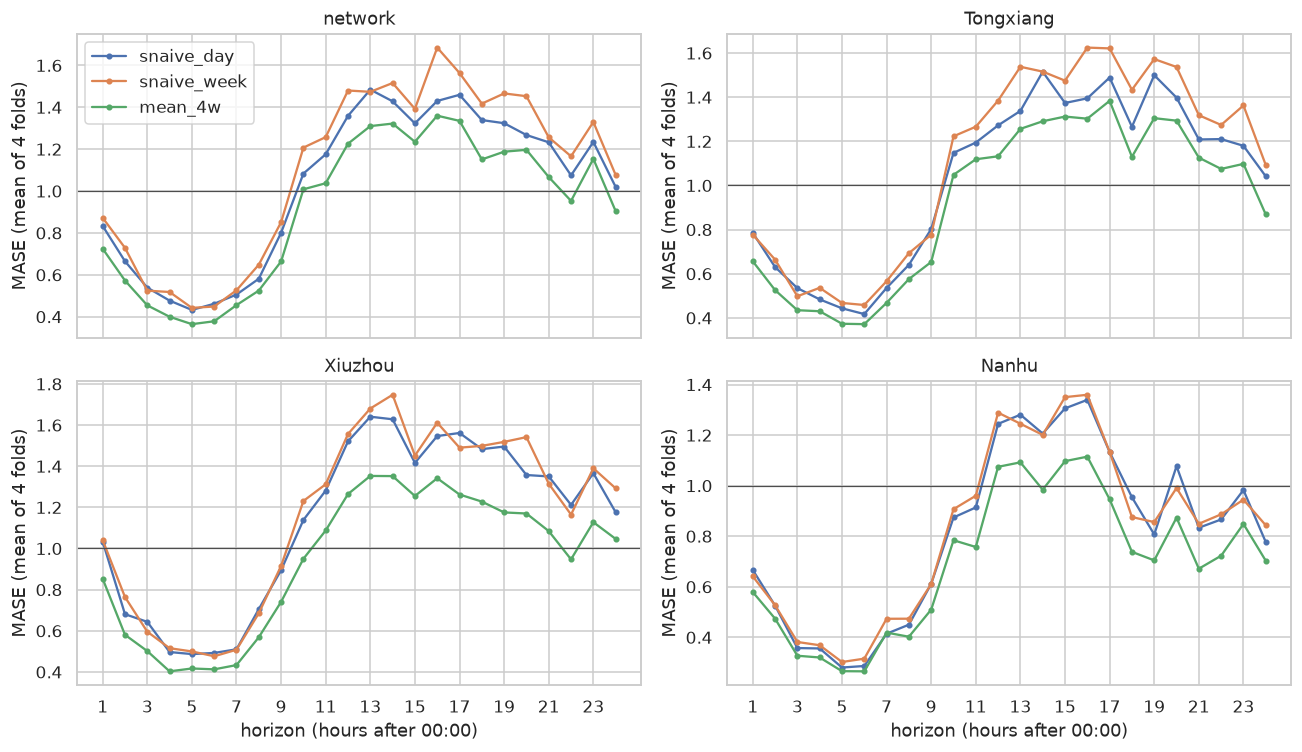

primary score (MASE): per fold and overall


fold,1,2,3,4,primary
method,,,,,
snaive_day,1.007,0.827,0.999,1.167,1.000
snaive_week,1.066,0.860,1.048,1.216,1.047
mean_4w,0.854,0.782,0.829,1.012,0.869


mean MASE per level (over horizons and folds)


level,network,Tongxiang,Xiuzhou,Nanhu
method,,,,
snaive_day,1.022,1.033,1.130,0.814
snaive_week,1.096,1.111,1.158,0.824
mean_4w,0.916,0.926,0.940,0.695


secondary scores per level, mean over horizons and folds (MAE and RMSE in sessions per hour)


mae                            rmse                            mase                          
level       Nanhu Tongxiang Xiuzhou network Nanhu Tongxiang Xiuzhou network Nanhu Tongxiang Xiuzhou network
method                                                                                                     
snaive_day  2.270     4.538   4.361   7.137 3.016     5.887   5.673   9.203 0.814     1.033   1.130   1.022
snaive_week 2.297     4.880   4.471   7.652 3.068     6.290   5.799   9.850 0.824     1.111   1.158   1.096
mean_4w     1.936     4.071   3.627   6.400 2.536     5.174   4.698   8.223 0.695     0.926   0.940   0.916

mean MASE by day type of the target day


period,normal weekday,weekend,holiday,adjusted working day
method,,,,
snaive_day,0.975,1.031,1.142,0.909
snaive_week,1.043,1.038,1.136,1.089
mean_4w,0.865,0.844,0.985,0.891


In [24]:
BASELINES = {"snaive_day": "lag_24", "snaive_week": "lag_168", "mean_4w": "same_hour_mean_4w"}

with timed("7 Evaluation protocol"):
    scored, by_period = [], []
    for fold in FOLDS["fold"]:
        v = fold_rows(fold, "validation")
        v["month"] = v["target_hour"].dt.strftime("%Y-%m")
        v["day_type"] = DAY_TYPE.reindex(v["target_hour"].dt.normalize()).to_numpy()
        for method, col in BASELINES.items():
            e = v.assign(abs_err=(v[col] - v["target"]).abs(), sq_err=(v[col] - v["target"]) ** 2)
            g = e.groupby(["level", "horizon"]).agg(mae=("abs_err", "mean"), mse=("sq_err", "mean")).reset_index()
            g["scale"] = [SCALES[(lvl, fold)] for lvl in g["level"]]
            g["rmse"] = np.sqrt(g.pop("mse"))
            g["mase"] = g["mae"] / g["scale"]
            g.insert(0, "fold", fold)
            g.insert(0, "method", method)
            scored.append(g)
            for kind in ["month", "day_type"]:
                p = e.groupby(["level", kind]).agg(n_rows=("abs_err", "size"), mae=("abs_err", "mean"),
                                                   mse=("sq_err", "mean")).reset_index()
                p = p.rename(columns={kind: "period"})
                p["rmse"] = np.sqrt(p.pop("mse"))
                p["mase"] = p["mae"] / [SCALES[(lvl, fold)] for lvl in p["level"]]
                p.insert(0, "period_kind", kind)
                p.insert(0, "fold", fold)
                p.insert(0, "method", method)
                by_period.append(p)

    scores = pd.concat(scored, ignore_index=True)[["method", "level", "fold", "horizon", "mae", "rmse", "mase",
                                                   "scale"]]
    scores_by_period = pd.concat(by_period, ignore_index=True)[["method", "level", "fold", "period_kind", "period",
                                                                "n_rows", "mae", "rmse", "mase"]]
    assert len(scores) == 3 * 4 * 4 * 24 == 1_152
    assert set(scores_by_period["period_kind"]) == {"month", "day_type"}
    scores.round(6).to_csv(OUT / "task1_baseline_scores.csv", index=False)
    scores_by_period.round(6).to_csv(OUT / "task1_baseline_scores_by_period.csv", index=False)

    overall, per_fold = primary_score(scores)
    primary = per_fold.assign(primary=overall).loc[list(BASELINES)]
    secondary = (scores.groupby(["method", "level"])[["mae", "rmse", "mase"]].mean()
                       .unstack("level").reindex(list(BASELINES)))
    per_level_mase = scores.groupby(["method", "level"])["mase"].mean().unstack("level")[LEVELS].loc[list(BASELINES)]
    day_type_table = (scores_by_period[(scores_by_period["period_kind"] == "day_type")]
                      .groupby(["method", "period"])["mase"].mean().unstack("period")
                      .reindex(index=list(BASELINES), columns=TYPES))

    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    by_h = scores.groupby(["method", "level", "horizon"])["mase"].mean()
    for ax, lvl in zip(axes.flat, LEVELS):
        for method in BASELINES:
            ax.plot(range(1, 25), by_h.loc[(method, lvl)].values, marker="o", ms=3, label=method)
        ax.axhline(1, color="0.3", lw=0.8)
        ax.set(title=lvl, ylabel="MASE (mean of 4 folds)", xticks=range(1, 25, 2))
    for ax in axes[1]:
        ax.set_xlabel("horizon (hours after 00:00)")
    axes[0, 0].legend()
    fig.tight_layout()
    save_fig("07_5_baselines_by_horizon", fig)
    plt.show()

print("primary score (MASE): per fold and overall")
display(primary)
print("mean MASE per level (over horizons and folds)")
display(per_level_mase)
print("secondary scores per level, mean over horizons and folds (MAE and RMSE in sessions per hour)")
display(secondary)
print("mean MASE by day type of the target day")
display(day_type_table)

reference = overall.idxmin()
results["primary_score"] = {m: r(v) for m, v in overall.items()}
results["primary_score_per_fold"] = {m: {str(f): r(v) for f, v in row.items()} for m, row in per_fold.iterrows()}
results["mase_per_level"] = {m: {lvl: r(v) for lvl, v in row.items()} for m, row in per_level_mase.iterrows()}
results["mae_per_level"] = {m: {lvl: r(secondary.at[m, ("mae", lvl)], 3) for lvl in LEVELS} for m in BASELINES}
results["rmse_per_level"] = {m: {lvl: r(secondary.at[m, ("rmse", lvl)], 3) for lvl in LEVELS} for m in BASELINES}
results["mase_by_day_type"] = {m: {t: r(v) for t, v in row.items()} for m, row in day_type_table.iterrows()}
results["reference_baseline"] = reference
add_decision(
    "D14", "7.5",
    f"{reference} is the reference baseline: every later model must beat its primary score on the same folds; the "
    "other two baselines are reported beside it.",
    "Primary MASE " + ", ".join(f"{m} {overall[m]:.3f}" for m in BASELINES) + "; per fold for "
    + f"{reference}: " + ", ".join(f"{v:.3f}" for v in per_fold.loc[reference]) + ".",
)

The four-week mean is the best of the three, with a primary MASE of 0.869, against 1.000 for the daily seasonal naive
and 1.047 for the weekly one. It wins in every fold (0.854, 0.782, 0.829 and 1.012) and at every level: averaging
four weeks removes much of the hour-to-hour noise that a single copied value carries. The weekly naive is the worst,
as the weak weekly pattern of Section 5.2 suggested.

The errors depend strongly on the hour. All three baselines have a MASE around 0.4 in the night hours, when few
sessions start. For the network and the two larger districts they go above 1 for most hours between 10:00 and 20:00,
when demand is high and changes most from day to day; Nanhu stays closer to 1. The fourth
fold is the hardest for all of them (MASE 1.012 for the four-week mean), because demand grew fast in the third quarter
of 2021, and holidays are the hardest day type (0.985 for the four-week mean against 0.865 on normal weekdays). In
sessions, the four-week mean misses the network by 6.4 sessions per hour on average (RMSE 8.2) and Nanhu by 1.9. We
take the four-week mean as the reference baseline: a model is useful only if it beats 0.869 on the same folds.

## 8 Saved files and integrity checks

Everything later tasks need is saved in `prepared/`. The protocol file holds the problem definition, the data
fingerprint, the periods, the folds, the predictors with the leakage rule, the metrics, the breakdowns and the
baselines; with the hourly series it is enough to rebuild the folds and recompute any baseline score. The run date
and the run times go to a separate file, so a second run leaves every other file identical. The cell reloads each
file and checks it.

In [25]:
with timed("8 Saved files and integrity checks"):
    protocol = {
        "problem": {
            "target": "sessions starting per hour", "levels": LEVELS,
            "issuance": "daily at 00:00, data up to the hour starting at 23:00 of the previous day",
            "horizons": {"from": 1, "to": 24}, "horizon_rule": "horizon h is clock hour h-1 of the issuance day",
            "strategy": "direct, one shared model, hour of day as input",
        },
        "data": {
            "file": "Charging_Data.csv", "sha256": sha256, "encoding": ENCODING, "rows_read": rows_read,
            "series_rule": "count by start hour per district; network = sum of districts; zero-filled; "
                           f"gap = network run >= {GAP_HOURS} h with no session",
            "series_file": "task1_hourly_series.csv",
        },
        "periods": {"series_from": "2020-01-01", "train_from": str(TRAIN_FROM.date()), "test_from": str(TEST_FROM.date()),
                    "test_until": "2021-12-31", "test_rows": test_rows},
        "folds": FOLDS[["fold", *DATE_COLS]].to_dict("records"),
        "predictors": {
            "include": catalogue.loc[catalogue["decision"] == "include", "name"].tolist(),
            "candidate": catalogue.loc[catalogue["decision"] == "candidate", "name"].tolist(),
            "exclude": catalogue.loc[catalogue["decision"] == "exclude", "name"].tolist(),
            "target_lags": TARGET_LAGS,
            "issuance_windows_days": {k: list(v) for k, v in ISSUANCE_WINDOWS.items()},
            "leakage_rule": "every input hour of every row is before the issuance D 00:00",
            "min_target_lag_hours": min(min(l) for l in TARGET_LAGS.values()),
            "issuance_anchored_window_end": "hour starting at D-1 23:00",
            "gap_rule": "a row is left out if its target hour or any input hour is a gap",
        },
        "metrics": {
            "list": ["MAE", "RMSE", "MASE"], "mase_period": MASE_M,
            "mase_scale": "in-sample seasonal naive MAE on the fold training hours, per level, gap hours left out",
            "primary": "MASE: mean over horizons, then levels (equal weight), then folds",
        },
        "breakdowns": {"horizon": "1 to 24", "level": LEVELS, "time_period": ["fold", "month", "day_type"],
                       "day_type": TYPES},
        "baselines": {"snaive_day": "lag 24", "snaive_week": "lag 168",
                      "mean_4w": "mean of lags 168, 336, 504, 672", "reference": reference},
        "test_protection": "test rows dropped right after parsing start time; only the count saved; "
                           "not scored in Task 1",
    }
    (OUT / "task1_protocol.json").write_text(json.dumps(protocol, indent=2, ensure_ascii=False) + "\n")
    (OUT / "task1_results.json").write_text(json.dumps(results, indent=2, ensure_ascii=False) + "\n")
    pd.DataFrame(decisions).to_csv(OUT / "task1_decision_log.csv", index=False)

    # reload every file and check it
    s = pd.read_csv(OUT / "task1_hourly_series.csv", parse_dates=["hour"])
    assert len(s) == 15_336 and s["hour"].is_unique and s["hour"].max() == pd.Timestamp("2021-09-30 23:00")
    assert (s["network"] == s[DISTRICTS].sum(axis=1)).all()
    p = json.loads((OUT / "task1_protocol.json").read_text())
    assert set(p) == {"problem", "data", "periods", "folds", "predictors", "metrics", "breakdowns", "baselines",
                      "test_protection"} and len(p["folds"]) == 4
    assert len(pd.read_csv(OUT / "task1_baseline_scores.csv")) == 1_152
    assert set(pd.read_csv(OUT / "task1_baseline_scores_by_period.csv")["period_kind"]) == {"month", "day_type"}
    log = pd.read_csv(OUT / "task1_decision_log.csv", dtype=str)
    assert log["id"].is_unique and len(log) == 14
    for name in ["task1_calendar.csv", "task1_audit.csv", "task1_predictor_catalogue.csv", "task1_folds.csv",
                 "task1_learned_operations_ledger.csv"]:
        assert (OUT / name).exists(), name
    n_figures = len(list(FIG.glob("*.png")))

total_seconds = round(time.perf_counter() - RUN_STARTED, 1)
run_info = {
    "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "section_times_seconds": section_times,
    "total_seconds": total_seconds,
    "python": sys.version.split()[0],
    "packages": {"pandas": pd.__version__, "numpy": np.__version__, "matplotlib": matplotlib.__version__,
                 "seaborn": sns.__version__},
}
(OUT / "task1_run_info.json").write_text(json.dumps(run_info, indent=2) + "\n")

print(f"all saved files reloaded and checked; {n_figures} figures in {FIG}")
display(pd.Series(section_times, name="seconds").to_frame())
print(f"total run time: {total_seconds} s")

all saved files reloaded and checked; 10 figures in prepared/figures_task1


,seconds
2 Reading and checking the file,2.220
3 Data-quality audit,1.510
4 Hourly series,0.050
5 Exploratory analysis,3.050
6 Forecasting formulation,0.300
7 Evaluation protocol,0.800
8 Saved files and integrity checks,0.010


total run time: 8.2 s


## 9 Synthesis and decision log

We built the four hourly series from the original transaction file after checking that the file is complete
(441,077 rows, three districts, recorded fingerprint). The 80,081 sessions from 2021-10-01 on were dropped right
after reading and form the final test. The audit removed only the 17 sessions of 2019-12-31 and kept 360,979; the
flags on order, payment and energy fields describe how the system records sessions, and the zero-energy sessions
count as demand because each one started at a post. No data gap was found, and district zeros are real zero demand.

Demand has a strong daily cycle (8.5 times more sessions at 15:00 than at 05:00 for the network), a weak weekly one,
a level that grows unevenly by district (Xiuzhou +60% and Nanhu -30% from April-September 2020 to the same months
of 2021), and two
clear breaks: the lockdown of February 2020 and the Spring Festival of 2021 (-35%). Daily weather is recorded, but
only temperature moves with demand, mostly through the season.

Forecasts are issued every day at 00:00 for the 24 hours of that day, with a direct strategy and one shared model.
The inputs are lags of at least 24 hours from the target hour, totals of the previous day and week, and calendar
information; weather is a candidate that needs a forecast at issuance. Models are compared on the four Project 1
folds by MASE with m = 24, averaged over horizons, levels and folds, with MAE and RMSE per level beside it. The
reference baseline is the four-week same-hour mean, with a primary MASE of 0.869; the daily seasonal naive scores
1.000 and the weekly one 1.047. The decision log below lists each decision with its evidence.

In [26]:
with pd.option_context("display.max_colwidth", 200):
    display(pd.read_csv(OUT / "task1_decision_log.csv", dtype=str))

,id,section,decision,evidence
0,D01,2.2,"The final test period is 2021-10-01 to 2021-12-31, the same quarter as in Project 1. Its rows are dropped right after the start time is parsed, and only their count is kept.","The file covers 2019-12-31 21:27 to 2021-12-31 23:52; the last full quarter holds 80,081 of 441,077 rows (18.2%), and the earlier quarters stay for development."
1,D02,2.3,Public holidays and adjusted working days are known future information and enter the calendar as two flags.,"61 holiday days and 13 adjusted working days in 2020-2021, all published by the State Council months ahead (notices of 2019 No. 16, 2020 No. 27 and the January 2020 Spring Festival extension)."
2,D03,3,"Only rows that cannot be placed in an hour of the study period, rows outside the three districts and exact duplicates are removed; inconsistent but placed sessions are kept, because each one start...","17 rows removed (all of them before 2020-01-01), 360,979 kept, 80,081 held out; repeated user, post and start time: 0; other time field unreadable: 0; end before start: 0; payment before end: 72,0..."
3,D04,4,"A data gap is a network run of 24 or more hours with no session; gap hours stay in the series with a flag and are left out of training, scoring and the MASE scale. Every other zero is real zero de...","0 gap hours; the longest network run without a session is 12 hours (from 2020-02-13 23:00); from 2020-04-01 the share of zero hours is network 0.4%, Tongxiang 2.1%, Xiuzhou 6.5%, Nanhu 15.0%."
4,D05,5.3,"MASE is scaled with the daily seasonal naive forecast, m = 24.","From 2020-04-01 the autocorrelation at 24 hours is above that at 168 hours at every level (network 0.848 against 0.821, Tongxiang 0.788 against 0.748, Xiuzhou 0.662 against 0.642, Nanhu 0.590 agai..."
5,D06,5.4,"Holidays, the Spring Festival included, are kept as legitimate variation and described to models by the holiday and adjusted working day flags; no day is removed.","From 2020-04-01, network demand on holidays is 0.99 times that of normal weekdays and 0.91 times on adjusted working days; the 2021 Spring Festival week averaged 327 sessions per day against 504 (..."
6,D07,5.5,"Training rows start on 2020-04-01, which confirms the Project 1 boundary; January to March 2020 serve only as lag history.","Network sessions were 6,217 in January 2020, 1,391 in February and 6,392 in March, and 11,136 in April; the February collapse belongs to the first COVID-19 restrictions and not to the demand the m..."
7,D08,5.7,"Weather stays an exogenous candidate: a model may use it only as a daily forecast known at issuance, and Task 2 tests whether it helps.","Weather is recorded once per day and district; from 2020-04-01 its Spearman correlation with daily network demand is +0.62 for temperature, +0.04 for humidity and +0.01 for precipitation; rainy da..."
8,D09,6.1,"Forecasts are issued once a day at 00:00 with the data up to the hour starting at 23:00 of the previous day, for the 24 hours of the issuance day; horizon h is clock hour h-1.","Daily planning needs one forecast per day; at midnight the same hour of the previous day is known for every horizon, and that lag has autocorrelation 0.848 at network level (Section 5.3)."
9,D10,6.2,"The 24 values come from a direct strategy with one shared model: one row per (issuance, level, horizon), inputs known at 00:00 only, hour of day as an input, no forecast fed back as an input.","The layout gives 52,608 development rows; 24 separate models would each see 1/24 of them, and a recursive forecast would feed its own errors into later hours of the day (Ben Taieb et al., 2012)."
